# Qlumina Quantitative Strategies: Performance, Fee Restructuring & Portfolio Construction

In [61]:
import os
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.regression.rolling import RollingOLS
import matplotlib.pyplot as plt
import seaborn as sns

# Configure display and plot aesthetics
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'semibold'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.titleweight'] = 'bold'
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print("Environment configured successfully. Ready for quantitative analysis.")


Environment configured successfully. Ready for quantitative analysis.


In [62]:
# 1. Load the consolidated hedge fund dataset
data_path = '../data/concat_hf_data.csv'
if not os.path.exists(data_path):
    # Fallback to local path if executed from root
    data_path = './data/concat_hf_data.csv'

df_raw = pd.read_csv(data_path)

if 'date' in df_raw.columns:
    df_raw['date'] = pd.to_datetime(df_raw['date'])
    df_raw = df_raw.set_index('date')

# 2. Extract all funds starting with 'qlumina' and the benchmark 'sp500'
qlumina_cols = [c for c in df_raw.columns if c.startswith('qlumina') and c not in ['qlumina_dubai', 'qlumina_zurich']]
print(f"Discovered Qlumina strategies ({len(qlumina_cols)} funds): {qlumina_cols}")

# Extract active sample window
target_cols = qlumina_cols + ['sp500']
df_subset = df_raw[target_cols].dropna(subset=qlumina_cols, how='all').copy()

# Date alignment
start_dt = df_subset[qlumina_cols].dropna().index.min()
end_dt = df_subset[qlumina_cols].dropna().index.max()
df_subset = df_subset.loc[start_dt:end_dt]

print(f"\n--- Dataset Ingestion Summary ---")
print(f"Track Record Period : {start_dt.strftime('%Y-%m')} to {end_dt.strftime('%Y-%m')}")
print(f"Total Observations  : {len(df_subset)} months")
print(f"Missing Values Check (Qlumina funds):\n{df_subset[qlumina_cols].isna().sum().to_dict()}")
print(f"Missing Values Check (SP500): {df_subset['sp500'].isna().sum()} months")

df_subset[qlumina_cols].head()


Discovered Qlumina strategies (4 funds): ['qlumina_new_york', 'qlumina_miami', 'qlumina_kiruna', 'qlumina_zermatt']

--- Dataset Ingestion Summary ---
Track Record Period : 2020-01 to 2026-09
Total Observations  : 81 months
Missing Values Check (Qlumina funds):
{'qlumina_new_york': 0, 'qlumina_miami': 0, 'qlumina_kiruna': 0, 'qlumina_zermatt': 0}
Missing Values Check (SP500): 2 months


,qlumina_new_york,qlumina_miami,qlumina_kiruna,qlumina_zermatt
date,,,,
2020-01-01,-0.0580,0.0070,0.0390,0.2550
2020-02-01,0.0720,0.0700,0.0410,0.5340
2020-03-01,0.4330,0.0430,0.0530,0.1370
2020-04-01,0.1970,0.4090,-0.0100,0.0820
2020-05-01,0.3670,0.0510,-0.0170,0.1430


## Fee Restructuring Engine: 1% Management Fee & 30% Performance Fee (HWM)

,Fund,Gross CAGR,Net CAGR (30/1 HWM),Annualized Fee Drag,Gross Volatility,Net Volatility,Gross Sharpe,Net Sharpe
0,qlumina_new_york,148.63%,89.94%,58.69%,39.26%,29.91%,2.58,2.34
1,qlumina_miami,61.32%,39.48%,21.84%,21.17%,15.40%,2.40,2.26
2,qlumina_kiruna,26.36%,17.08%,9.28%,13.56%,10.15%,1.80,1.61
3,qlumina_zermatt,241.10%,140.16%,100.94%,44.64%,33.34%,3.08,2.88


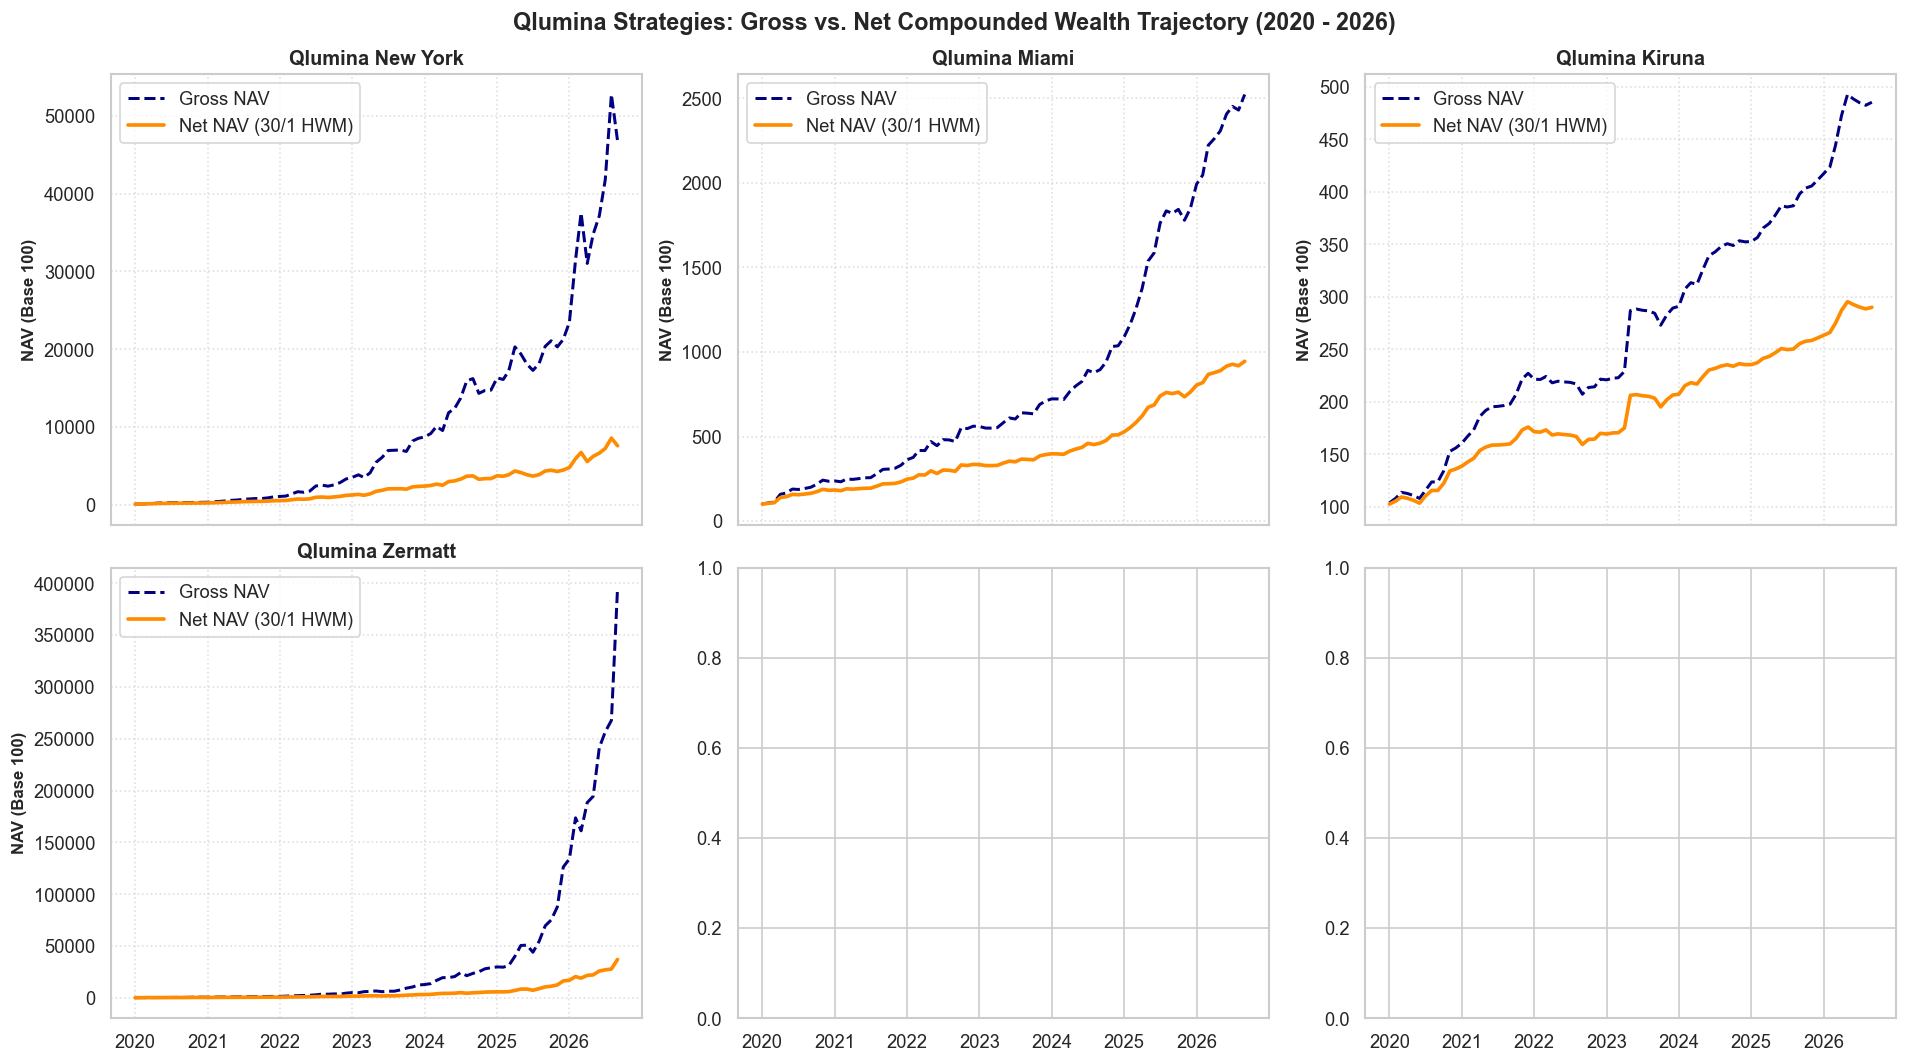

In [63]:
def apply_fund_fees(gross_series, mgmt_fee_annual=0.01, perf_fee_rate=0.30, method='hwm'):
    """
    Converts gross monthly return series to net monthly returns applying 
    management fee and performance fee under HWM accounting.
    """
    m_monthly = mgmt_fee_annual / 12.0
    
    if method == 'simple':
        # Simple monthly deduction without HWM
        net_ret = np.where(gross_series > 0, gross_series * (1.0 - perf_fee_rate), gross_series) - m_monthly
        return pd.Series(net_ret, index=gross_series.index, name=gross_series.name)
        
    elif method == 'hwm':
        nav = 100.0
        hwm = 100.0
        net_returns = []
        
        for r in gross_series:
            nav_gross = nav * (1.0 + r)
            nav_after_mgmt = nav_gross * (1.0 - m_monthly)
            
            if nav_after_mgmt > hwm:
                perf_fee = perf_fee_rate * (nav_after_mgmt - hwm)
                nav_net = nav_after_mgmt - perf_fee
                hwm = nav_net
            else:
                nav_net = nav_after_mgmt
                
            r_net = (nav_net / nav) - 1.0
            net_returns.append(r_net)
            nav = nav_net
            
        return pd.Series(net_returns, index=gross_series.index, name=gross_series.name)

# Apply fee engine to all Qlumina funds
df_gross = df_subset[qlumina_cols].copy()
df_net = df_gross.apply(lambda col: apply_fund_fees(col, mgmt_fee_annual=0.01, perf_fee_rate=0.30, method='hwm'))

# Fee Impact Comparison Table
fee_comparison = []
n_m = len(df_gross)
for col in qlumina_cols:
    g_cagr = (1 + df_gross[col]).prod() ** (12 / n_m) - 1
    n_cagr = (1 + df_net[col]).prod() ** (12 / n_m) - 1
    g_vol = df_gross[col].std() * np.sqrt(12)
    n_vol = df_net[col].std() * np.sqrt(12)
    fee_drag = g_cagr - n_cagr
    fee_comparison.append({
        'Fund': col,
        'Gross CAGR': f'{g_cagr:.2%}',
        'Net CAGR (30/1 HWM)': f'{n_cagr:.2%}',
        'Annualized Fee Drag': f'{fee_drag:.2%}',
        'Gross Volatility': f'{g_vol:.2%}',
        'Net Volatility': f'{n_vol:.2%}',
        'Gross Sharpe': f'{(df_gross[col].mean()*12)/g_vol:.2f}',
        'Net Sharpe': f'{(df_net[col].mean()*12)/n_vol:.2f}'
    })

df_fee_comp = pd.DataFrame(fee_comparison)
display(df_fee_comp)

# Plot Gross vs Net Cumulative Wealth Growth
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True)
axes = axes.flatten()

for idx, col in enumerate(qlumina_cols):
    ax = axes[idx]
    cum_gross = (1 + df_gross[col]).cumprod() * 100
    cum_net = (1 + df_net[col]).cumprod() * 100
    ax.plot(cum_gross, label='Gross NAV', color='navy', linestyle='--', linewidth=1.8)
    ax.plot(cum_net, label='Net NAV (30/1 HWM)', color='darkorange', linewidth=2.2)
    ax.set_title(col.replace('_', ' ').title(), fontweight='bold')
    ax.set_ylabel('NAV (Base 100)')
    ax.legend(loc='upper left', frameon=True)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.suptitle('Qlumina Strategies: Gross vs. Net Compounded Wealth Trajectory (2020 - 2026)', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


## Correlation Matrix Analysis: Monthly Net Returns

A core mandate in quantitative multi-strategy allocation is evaluating cross-strategy dependency structures:
- **Pearson Linear Correlation ($r$)**: Measures co-movement in dollar exposures and linear risk sensitivity.
- **Spearman Monotonic Rank Correlation ($\rho$)**: Evaluates rank agreement, providing robustness against non-linear regime shifts and extreme tail observations.


--- Pearson Correlation Matrix (Monthly Net Returns) ---


,qlumina_new_york,qlumina_miami,qlumina_kiruna,qlumina_zermatt
qlumina_new_york,1.0000,0.0669,0.2087,-0.0777
qlumina_miami,0.0669,1.0000,0.0221,0.0870
qlumina_kiruna,0.2087,0.0221,1.0000,0.1191
qlumina_zermatt,-0.0777,0.0870,0.1191,1.0000



--- Spearman Rank Correlation Matrix (Monthly Net Returns) ---


,qlumina_new_york,qlumina_miami,qlumina_kiruna,qlumina_zermatt
qlumina_new_york,1.0000,-0.0059,0.1741,-0.0687
qlumina_miami,-0.0059,1.0000,0.0535,0.1327
qlumina_kiruna,0.1741,0.0535,1.0000,0.1043
qlumina_zermatt,-0.0687,0.1327,0.1043,1.0000


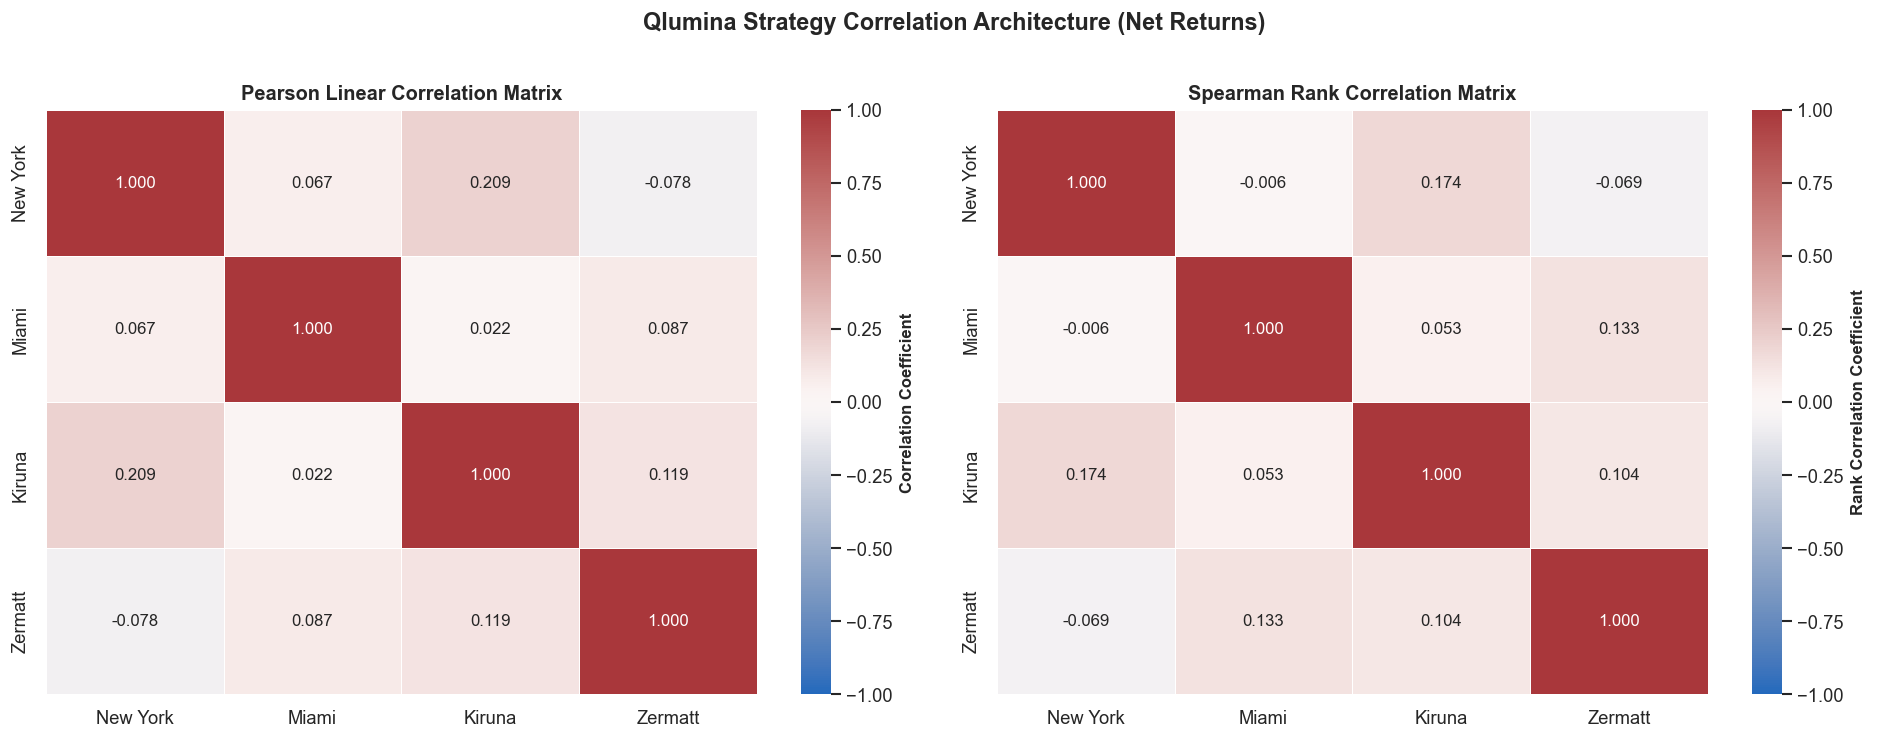

In [64]:
# 1. Compute Pearson and Spearman correlation matrices
pearson_corr = df_net.corr(method='pearson')
spearman_corr = df_net.corr(method='spearman')

print("--- Pearson Correlation Matrix (Monthly Net Returns) ---")
display(pearson_corr.round(4))

print("\n--- Spearman Rank Correlation Matrix (Monthly Net Returns) ---")
display(spearman_corr.round(4))

# 2. Visualize with side-by-side heatmaps
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

clean_labels = [c.replace('qlumina_', '').replace('_', ' ').title() for c in qlumina_cols]

sns.heatmap(pearson_corr, annot=True, fmt='.3f', cmap='vlag', vmin=-1, vmax=1, 
            xticklabels=clean_labels, yticklabels=clean_labels, ax=axes[0],
            cbar_kws={'label': 'Correlation Coefficient'}, linewidths=0.5)
axes[0].set_title('Pearson Linear Correlation Matrix', fontweight='bold', fontsize=12)

sns.heatmap(spearman_corr, annot=True, fmt='.3f', cmap='vlag', vmin=-1, vmax=1, 
            xticklabels=clean_labels, yticklabels=clean_labels, ax=axes[1],
            cbar_kws={'label': 'Rank Correlation Coefficient'}, linewidths=0.5)
axes[1].set_title('Spearman Rank Correlation Matrix', fontweight='bold', fontsize=12)

plt.suptitle('Qlumina Strategy Correlation Architecture (Net Returns)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Single-Fund Comprehensive Performance Analysis

In alignment with `single_fund_analysis/general_analysis.ipynb`, we now systematically evaluate each Qlumina strategy.
For each individual fund, we compute:
1. **Dataset Info & Hit Rates**: Positive months, SP500 positive months, conditional hit rate in down SP500 markets.
2. **Performance in Worst 10% / 20% SP500 Months**: Bar plot tracking hedging efficacy during market distress.
3. **Yearly Calendar Returns**: Annual performance breakdown (2020 through 2026).
4. **Core Trading Metrics**:
   - Annualized Mean Return, Annualized Volatility, Sharpe Ratio ($R_f=0$), CAGR, Max Drawdown (MDD), Calmar Ratio, Sortino Ratio.
5. **Underwater Drawdown Dynamics**: Visualizing drawdown severity and recovery profile.
6. **Joint Benchmark Metrics (S&P 500)**:
   - Pearson & Spearman correlations.
   - 95% Bootstrap Confidence Intervals: Standard i.i.d. Bootstrap & Moving Block Bootstrap ($block\_size = 3$).
   - OLS Alpha (Annualized) & Beta with t-statistics and $R^2$.
   - Upside & Downside Capture Ratios.
   - Conditional Regime Metrics: Up Months Alpha/Beta & Down Months Alpha/Beta.
   - Tail Correlations: Correlation when SP500 is below 1st decile and 1st quartile.
7. **Rolling Dynamics**: 12-Month & 24-Month Rolling Correlation, Beta, and Alpha relative to S&P 500.


In [65]:
def bootstrap_corr_ci(x, y, method='pearson', block_size=1, iters=1000, alpha=0.05):
    """Calculates bootstrap confidence intervals for correlation."""
    np.random.seed(42)
    n = len(x)
    corrs = []
    indices = np.arange(n)
    for _ in range(iters):
        if block_size == 1:
            idx = np.random.choice(indices, size=n, replace=True)
        else:
            num_blocks = int(np.ceil(n / block_size))
            starts = np.random.choice(n - block_size + 1, size=num_blocks, replace=True)
            idx = [i for s in starts for i in range(s, s + block_size)][:n]
        x_samp = x.iloc[idx]
        y_samp = y.iloc[idx]
        corrs.append(x_samp.corr(y_samp, method=method))
    lower = np.nanpercentile(corrs, 100 * (alpha / 2))
    upper = np.nanpercentile(corrs, 100 * (1 - alpha / 2))
    return lower, upper

def run_single_fund_analysis(fund_series, bmk_series, fund_label, display_plots=True):
    """
    Executes the full suite of quantitative metrics from single_fund_analysis/general_analysis.ipynb.
    Returns a dictionary of all computed metrics.
    """
    # Align fund and benchmark
    aligned = pd.concat([fund_series, bmk_series], axis=1).dropna()
    fund = aligned.iloc[:, 0]
    sp500 = aligned.iloc[:, 1]
    
    n_months = len(fund)
    start_date = fund.index.min()
    end_date = fund.index.max()
    time_elapsed = end_date - start_date
    years_elapsed = time_elapsed.days / 365.25
    
    # Hit rates
    fund_pos = (fund > 0).sum()
    sp500_pos = (sp500 > 0).sum()
    sp500_neg_mask = sp500 < 0
    sp500_pos_mask = sp500 > 0
    n_sp500_neg = sp500_neg_mask.sum()
    n_sp500_pos = sp500_pos_mask.sum()
    
    fund_pos_when_sp_neg = (fund[sp500_neg_mask] > 0).sum()
    fund_neg_when_sp_pos = (fund[sp500_pos_mask] < 0).sum()
    
    # Core trading metrics
    mean_ret = fund.mean() * 12
    vol = fund.std() * np.sqrt(12)
    sharpe = mean_ret / vol if vol != 0 else np.nan
    cum_ret = (1 + fund).prod()
    cagr = cum_ret ** (12 / n_months) - 1
    
    cum_wealth = (1 + fund).cumprod()
    peak = cum_wealth.cummax()
    drawdown = (cum_wealth - peak) / peak
    max_drawdown = drawdown.min()
    calmar = cagr / abs(max_drawdown) if max_drawdown != 0 else np.nan
    
    downside_rets = fund[fund < 0]
    downside_dev = np.sqrt((downside_rets**2).mean()) * np.sqrt(12)
    sortino = mean_ret / downside_dev if downside_dev != 0 else np.nan
    
    # Joint metrics with S&P 500
    pearson_corr = fund.corr(sp500, method='pearson')
    spearman_corr = fund.corr(sp500, method='spearman')
    
    p_std_ci = bootstrap_corr_ci(fund, sp500, method='pearson', block_size=1)
    p_blk_ci = bootstrap_corr_ci(fund, sp500, method='pearson', block_size=3)
    s_std_ci = bootstrap_corr_ci(fund, sp500, method='spearman', block_size=1)
    s_blk_ci = bootstrap_corr_ci(fund, sp500, method='spearman', block_size=3)
    
    # OLS Regression
    X = sm.add_constant(sp500)
    model = sm.OLS(fund, X).fit()
    alpha = model.params['const'] * 12
    beta = model.params.iloc[1]
    alpha_t = model.tvalues['const']
    beta_t = model.tvalues.iloc[1]
    alpha_p = model.pvalues['const']
    beta_p = model.pvalues.iloc[1]
    r_squared = model.rsquared
    
    # Capture ratios
    up_fund = fund[sp500_pos_mask]
    up_sp = sp500[sp500_pos_mask]
    down_fund = fund[sp500_neg_mask]
    down_sp = sp500[sp500_neg_mask]
    up_capture = up_fund.mean() / up_sp.mean() if len(up_sp) > 0 else np.nan
    down_capture = down_fund.mean() / down_sp.mean() if len(down_sp) > 0 else np.nan
    
    # Conditional OLS
    up_df = aligned[sp500_pos_mask]
    down_df = aligned[sp500_neg_mask]
    model_up = sm.OLS(up_df.iloc[:, 0], sm.add_constant(up_df.iloc[:, 1])).fit()
    model_down = sm.OLS(down_df.iloc[:, 0], sm.add_constant(down_df.iloc[:, 1])).fit()
    up_alpha = model_up.params['const'] * 12
    up_beta = model_up.params.iloc[1]
    down_alpha = model_down.params['const'] * 12
    down_beta = model_down.params.iloc[1]
    
    # Tail correlations
    d1 = sp500.quantile(0.10)
    df_d1 = aligned[aligned.iloc[:, 1] < d1]
    d1_p = df_d1.iloc[:, 0].corr(df_d1.iloc[:, 1], method='pearson')
    d1_s = df_d1.iloc[:, 0].corr(df_d1.iloc[:, 1], method='spearman')
    
    q1 = sp500.quantile(0.25)
    df_q1 = aligned[aligned.iloc[:, 1] < q1]
    q1_p = df_q1.iloc[:, 0].corr(df_q1.iloc[:, 1], method='pearson')
    q1_s = df_q1.iloc[:, 0].corr(df_q1.iloc[:, 1], method='spearman')
    
    print(f"=========================================================================")
    print(f"                  QUANTITATIVE REPORT: {fund_label.upper()}               ")
    print(f"=========================================================================")
    print(f"--- Dataset Info ---")
    print(f"Period: {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')} ({years_elapsed:.2f} yrs, {n_months} months)")
    print(f"\n--- Hit Rates & Asymmetry ---")
    print(f"Fund Positive Months     : {fund_pos/n_months:.2%} ({fund_pos}/{n_months})")
    print(f"SP500 Positive Months    : {sp500_pos/n_months:.2%} ({sp500_pos}/{n_months})")
    print(f"Fund Pos when SP500 Neg  : {fund_pos_when_sp_neg/n_sp500_neg:.2%} ({fund_pos_when_sp_neg}/{n_sp500_neg}) [Downside Independence]")
    print(f"Fund Neg when SP500 Pos  : {fund_neg_when_sp_pos/n_sp500_pos:.2%} ({fund_neg_when_sp_pos}/{n_sp500_pos})")
    print(f"\n--- Core Performance & Risk Metrics ---")
    print(f"CAGR                     : {cagr:.4f} ({cagr:.2%})")
    print(f"Annualized Mean Return   : {mean_ret:.4f} ({mean_ret:.2%})")
    print(f"Annualized Volatility    : {vol:.4f} ({vol:.2%})")
    print(f"Sharpe Ratio (Rf=0)      : {sharpe:.4f}")
    print(f"Sortino Ratio            : {sortino:.4f}")
    print(f"Max Drawdown (MDD)       : {max_drawdown:.4f} ({max_drawdown:.2%})")
    print(f"Calmar Ratio             : {calmar:.4f}")
    print(f"\n--- Factor & Joint Metrics vs S&P 500 ---")
    print(f"Pearson Correlation      : {pearson_corr:.4f}")
    print(f"  - 95% CI (i.i.d.): [{p_std_ci[0]:.4f}, {p_std_ci[1]:.4f}] | (Block=3): [{p_blk_ci[0]:.4f}, {p_blk_ci[1]:.4f}]")
    print(f"Spearman Correlation     : {spearman_corr:.4f}")
    print(f"  - 95% CI (i.i.d.): [{s_std_ci[0]:.4f}, {s_std_ci[1]:.4f}] | (Block=3): [{s_blk_ci[0]:.4f}, {s_blk_ci[1]:.4f}]")
    print(f"Regression Alpha (Ann.)  : {alpha:.4f} (t-stat: {alpha_t:.2f}, p-val: {alpha_p:.4f})")
    print(f"Regression Beta          : {beta:.4f} (t-stat: {beta_t:.2f}, p-val: {beta_p:.4f})")
    print(f"Regression R-squared     : {r_squared:.4f}")
    print(f"Upside Capture Ratio     : {up_capture:.4f}")
    print(f"Downside Capture Ratio   : {down_capture:.4f}")
    print(f"Up Months Alpha (Ann.)   : {up_alpha:.4f} | Up Beta: {up_beta:.4f}")
    print(f"Down Months Alpha (Ann.) : {down_alpha:.4f} | Down Beta: {down_beta:.4f}")
    print(f"Tail Corr (SP < 1st Dec.): Pearson: {d1_p:.4f}, Spearman: {d1_s:.4f} (n={len(df_d1)})")
    print(f"Tail Corr (SP < 1st Qrt.): Pearson: {q1_p:.4f}, Spearman: {q1_s:.4f} (n={len(df_q1)})")
    
    if display_plots:
        # Plot 1: Performance during Worst 10% SP500 Months & Yearly Returns
        fig, axes = plt.subplots(1, 2, figsize=(16, 5))
        
        # Worst SP500 Months
        q10_thresh = sp500.quantile(0.10)
        worst_sp_df = aligned[aligned.iloc[:, 1] <= q10_thresh].sort_values(by=aligned.columns[1])
        plot_worst = worst_sp_df * 100
        plot_worst.index = plot_worst.index.strftime('%Y-%m')
        
        plot_worst.columns = [fund_label, 'SP500']
        plot_worst[[ 'SP500', fund_label]].plot(kind='bar', ax=axes[0], color=['firebrick', 'steelblue'], width=0.8)
        axes[0].set_title(f'Performance During Worst 10% SP500 Months ({fund_label})', fontweight='bold')
        axes[0].set_ylabel('Monthly Return (%)')
        axes[0].axhline(0, color='black', linewidth=0.8)
        axes[0].tick_params(axis='x', rotation=45)
        axes[0].grid(True, linestyle=':', alpha=0.6)
        
        # Yearly Returns
        yearly_ret = ((1 + aligned).groupby(aligned.index.year).prod() - 1) * 100
        yearly_ret.columns = [fund_label, 'SP500']
        yearly_ret[['SP500', fund_label]].plot(kind='bar', ax=axes[1], color=['firebrick', 'steelblue'], width=0.8)
        axes[1].set_title(f'Calendar Year Returns: {fund_label} vs SP500', fontweight='bold')
        axes[1].set_ylabel('Annual Return (%)')
        axes[1].axhline(0, color='black', linewidth=0.8)
        axes[1].tick_params(axis='x', rotation=0)
        axes[1].grid(True, linestyle=':', alpha=0.6)
        
        plt.tight_layout()
        plt.show()
        
        # Plot 2: Drawdown Underwater Profile
        fig, ax = plt.subplots(figsize=(16, 4))
        ax.fill_between(drawdown.index, drawdown * 100, 0, color='indianred', alpha=0.4, label='Underwater Drawdown')
        ax.plot(drawdown * 100, color='firebrick', linewidth=1.5)
        ax.set_title(f'Underwater Drawdown Profile: {fund_label} (Max DD: {max_drawdown:.2%})', fontweight='bold')
        ax.set_ylabel('Drawdown (%)')
        ax.axhline(0, color='black', linewidth=0.8)
        ax.grid(True, linestyle=':', alpha=0.6)
        plt.tight_layout()
        plt.show()
        
        # Plot 3: Rolling Metrics (12-Month & 24-Month)
        try:
            roll_corr_12 = fund.rolling(12).corr(sp500)
            roll_corr_24 = fund.rolling(24).corr(sp500)
            
            X_roll = sm.add_constant(sp500)
            roll_ols_12 = RollingOLS(fund, X_roll, window=12).fit()
            roll_alpha_12 = roll_ols_12.params['const'] * 12
            roll_beta_12 = roll_ols_12.params.iloc[:, 1]
            
            roll_ols_24 = RollingOLS(fund, X_roll, window=24).fit()
            roll_alpha_24 = roll_ols_24.params['const'] * 12
            roll_beta_24 = roll_ols_24.params.iloc[:, 1]
            
            fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)
            
            axes[0].plot(roll_corr_12, label='12-Month Rolling', color='steelblue', linewidth=1.8)
            axes[0].plot(roll_corr_24, label='24-Month Rolling', color='firebrick', linewidth=1.8)
            axes[0].axhline(0, color='gray', linestyle='--', linewidth=0.8)
            axes[0].set_title(f'Rolling Correlation with S&P 500: {fund_label}', fontweight='bold')
            axes[0].legend(loc='lower left')
            axes[0].grid(True, linestyle=':', alpha=0.6)
            
            axes[1].plot(roll_beta_12, label='12-Month Rolling', color='steelblue', linewidth=1.8)
            axes[1].plot(roll_beta_24, label='24-Month Rolling', color='firebrick', linewidth=1.8)
            axes[1].axhline(0, color='gray', linestyle='--', linewidth=0.8)
            axes[1].set_title(f'Rolling Beta relative to S&P 500: {fund_label}', fontweight='bold')
            axes[1].legend(loc='lower left')
            axes[1].grid(True, linestyle=':', alpha=0.6)
            
            axes[2].plot(roll_alpha_12, label='12-Month Rolling', color='steelblue', linewidth=1.8)
            axes[2].plot(roll_alpha_24, label='24-Month Rolling', color='firebrick', linewidth=1.8)
            axes[2].axhline(0, color='gray', linestyle='--', linewidth=0.8)
            axes[2].set_title(f'Rolling Annualized Alpha relative to S&P 500: {fund_label}', fontweight='bold')
            axes[2].legend(loc='lower left')
            axes[2].grid(True, linestyle=':', alpha=0.6)
            
            plt.tight_layout()
            plt.show()
        except Exception as e:
            print(f'Rolling metrics plot omitted: {e}')

    return {
        'Fund': fund_label,
        'CAGR': cagr,
        'Ann Return': mean_ret,
        'Ann Volatility': vol,
        'Sharpe Ratio': sharpe,
        'Sortino Ratio': sortino,
        'Max Drawdown': max_drawdown,
        'Calmar Ratio': calmar,
        'Hit Rate': fund_pos / n_months,
        'Pos in Down SP500': fund_pos_when_sp_neg / n_sp500_neg,
        'Pearson Corr': pearson_corr,
        'Spearman Corr': spearman_corr,
        'Alpha (Ann)': alpha,
        'Alpha t-stat': alpha_t,
        'Beta': beta,
        'Beta t-stat': beta_t,
        'R-squared': r_squared,
        'Upside Capture': up_capture,
        'Downside Capture': down_capture
    }

print("Quantitative Single Fund Analytics Engine ready.")


Quantitative Single Fund Analytics Engine ready.


In [66]:
# Single Fund Evaluation: qlumina_dubai
# m_qlumina_dubai = run_single_fund_analysis(df_net['qlumina_dubai'], df_subset['sp500'], 'qlumina_dubai', display_plots=True)


                  QUANTITATIVE REPORT: QLUMINA_NEW_YORK               
--- Dataset Info ---
Period: 2020-01-01 to 2026-07-01 (6.50 yrs, 79 months)

--- Hit Rates & Asymmetry ---
Fund Positive Months     : 82.28% (65/79)
SP500 Positive Months    : 63.29% (50/79)
Fund Pos when SP500 Neg  : 79.31% (23/29) [Downside Independence]
Fund Neg when SP500 Pos  : 16.00% (8/50)

--- Core Performance & Risk Metrics ---
CAGR                     : 0.9168 (91.68%)
Annualized Mean Return   : 0.7080 (70.80%)
Annualized Volatility    : 0.2913 (29.13%)
Sharpe Ratio (Rf=0)      : 2.4306
Sortino Ratio            : 2.8164
Max Drawdown (MDD)       : -0.1737 (-17.37%)
Calmar Ratio             : 5.2782

--- Factor & Joint Metrics vs S&P 500 ---
Pearson Correlation      : -0.0195
  - 95% CI (i.i.d.): [-0.3109, 0.2856] | (Block=3): [-0.2976, 0.2705]
Spearman Correlation     : 0.0898
  - 95% CI (i.i.d.): [-0.1613, 0.3203] | (Block=3): [-0.1571, 0.3294]
Regression Alpha (Ann.)  : 0.7132 (t-stat: 6.03, p-val: 0.0000

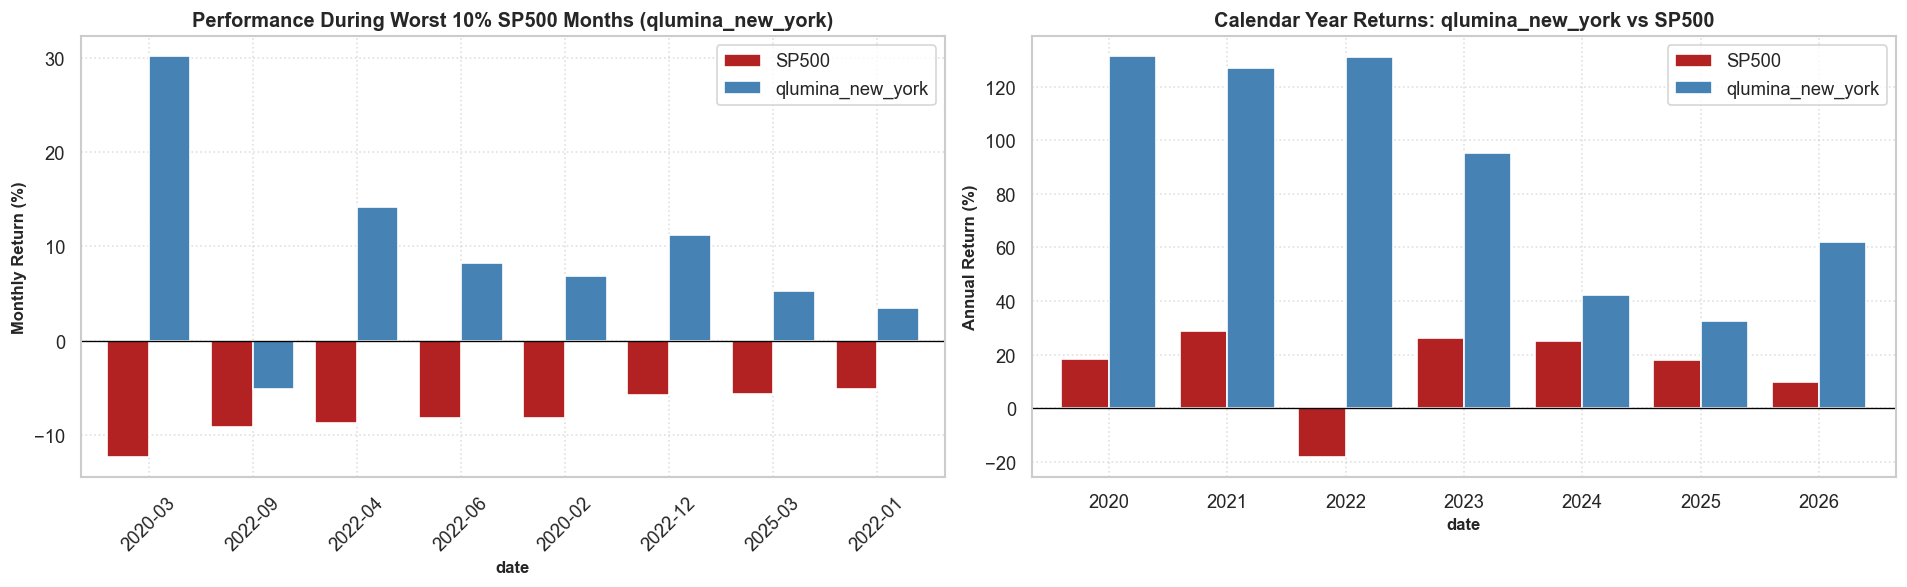

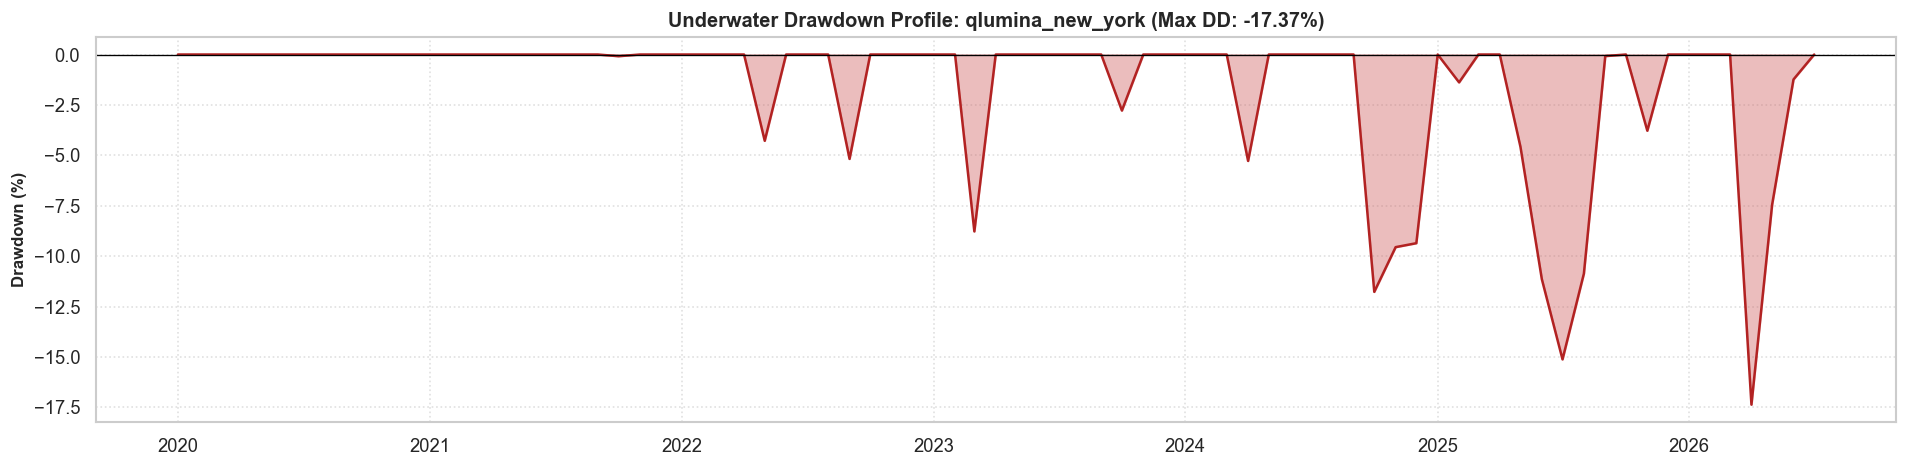

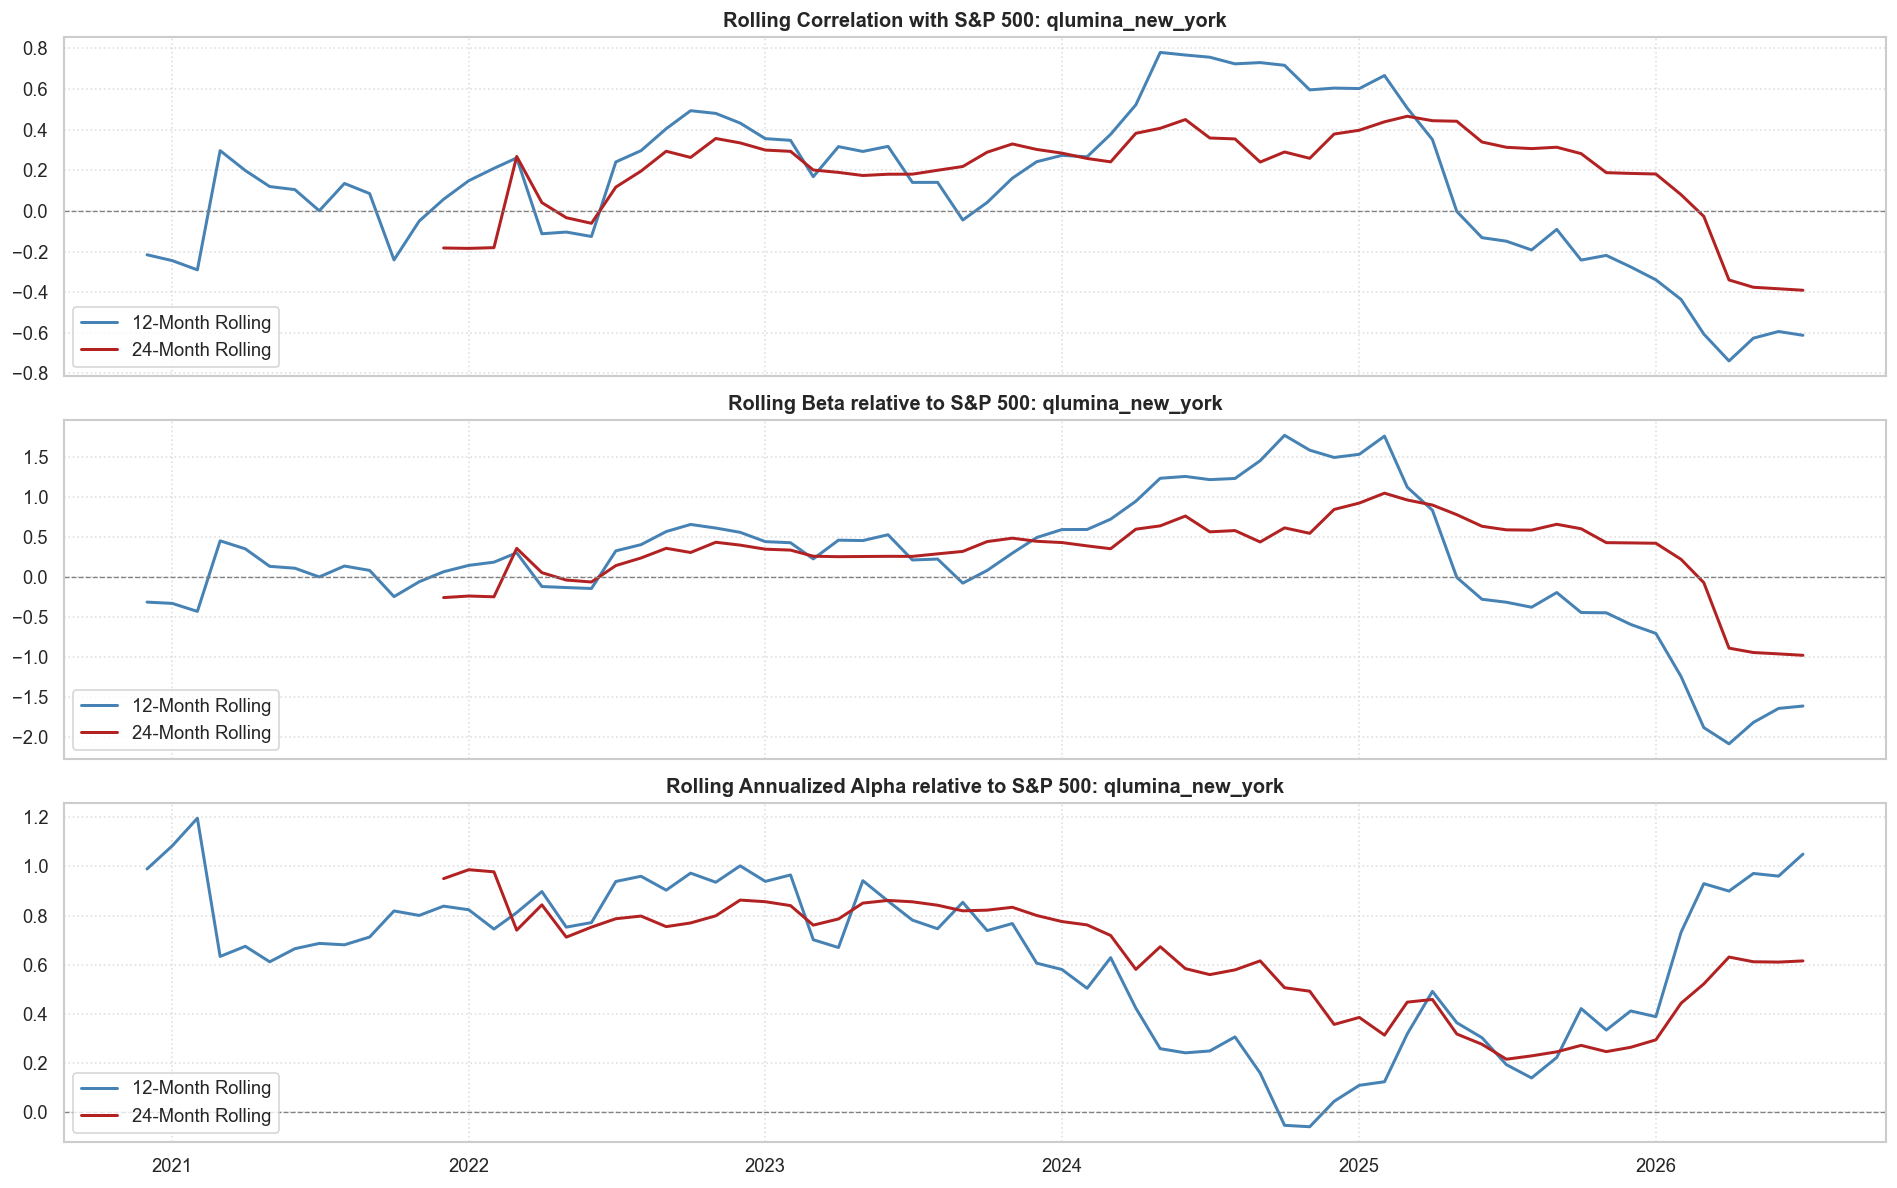

In [67]:
# Single Fund Evaluation: qlumina_new_york
m_qlumina_new_york = run_single_fund_analysis(df_net['qlumina_new_york'], df_subset['sp500'], 'qlumina_new_york', display_plots=True)


In [68]:
# Single Fund Evaluation: qlumina_zurich
# m_qlumina_zurich = run_single_fund_analysis(df_net['qlumina_zurich'], df_subset['sp500'], 'qlumina_zurich', display_plots=True)


                  QUANTITATIVE REPORT: QLUMINA_MIAMI               
--- Dataset Info ---
Period: 2020-01-01 to 2026-07-01 (6.50 yrs, 79 months)

--- Hit Rates & Asymmetry ---
Fund Positive Months     : 74.68% (59/79)
SP500 Positive Months    : 63.29% (50/79)
Fund Pos when SP500 Neg  : 75.86% (22/29) [Downside Independence]
Fund Neg when SP500 Pos  : 26.00% (13/50)

--- Core Performance & Risk Metrics ---
CAGR                     : 0.4026 (40.26%)
Annualized Mean Return   : 0.3540 (35.40%)
Annualized Volatility    : 0.1552 (15.52%)
Sharpe Ratio (Rf=0)      : 2.2809
Sortino Ratio            : 5.4625
Max Drawdown (MDD)       : -0.0528 (-5.28%)
Calmar Ratio             : 7.6271

--- Factor & Joint Metrics vs S&P 500 ---
Pearson Correlation      : 0.2887
  - 95% CI (i.i.d.): [-0.0193, 0.5013] | (Block=3): [-0.0637, 0.4905]
Spearman Correlation     : 0.0962
  - 95% CI (i.i.d.): [-0.1403, 0.3258] | (Block=3): [-0.1753, 0.3553]
Regression Alpha (Ann.)  : 0.3126 (t-stat: 5.18, p-val: 0.0000)
Re

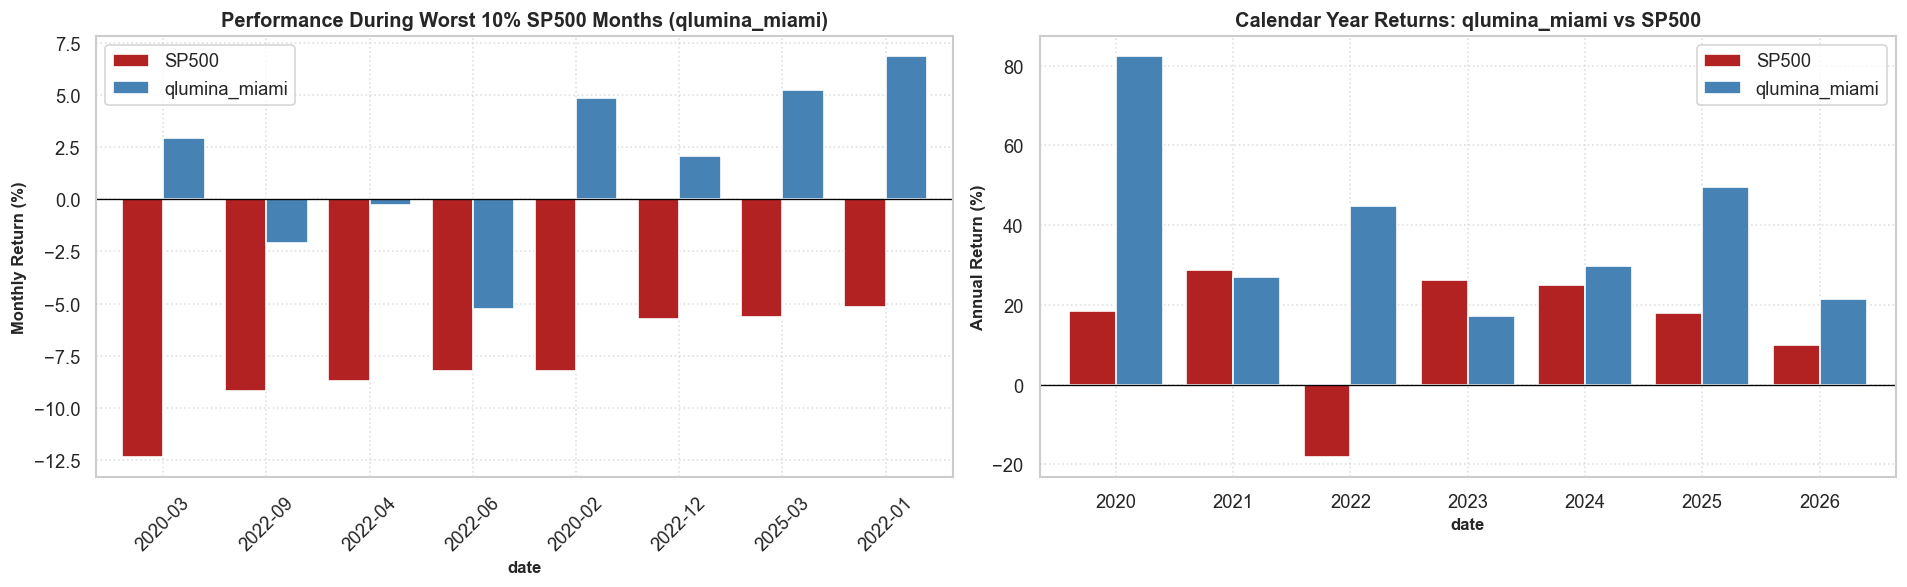

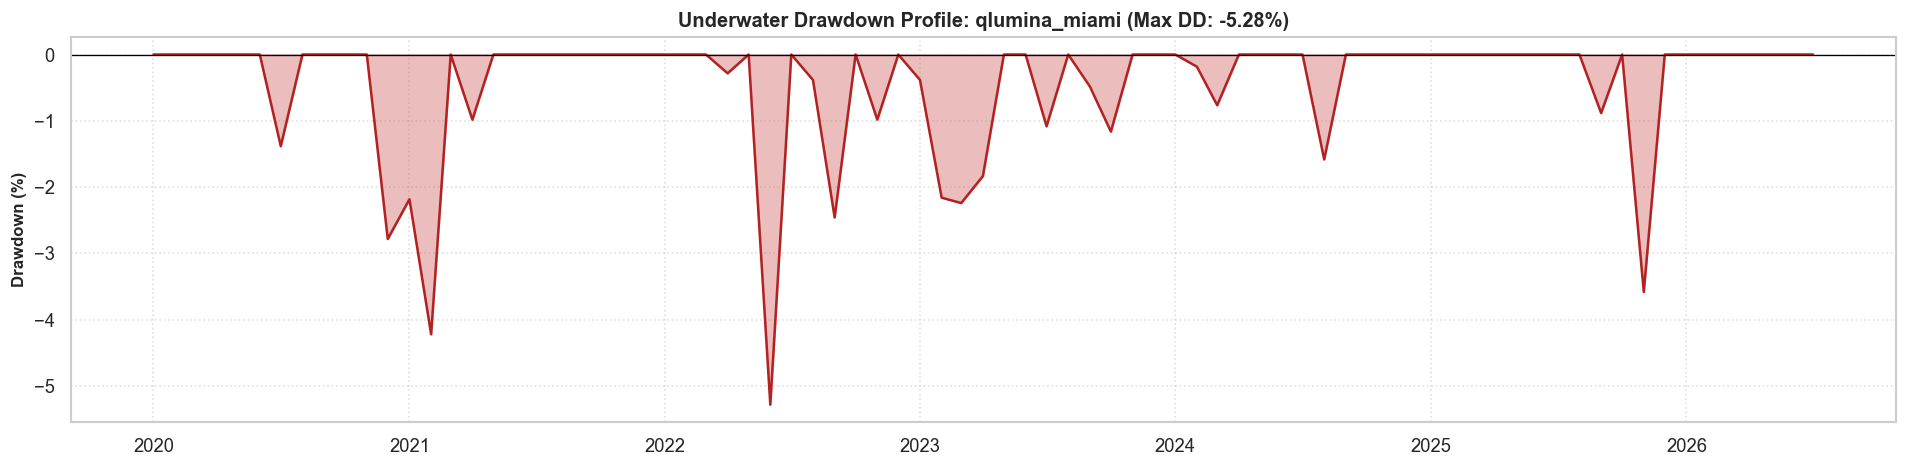

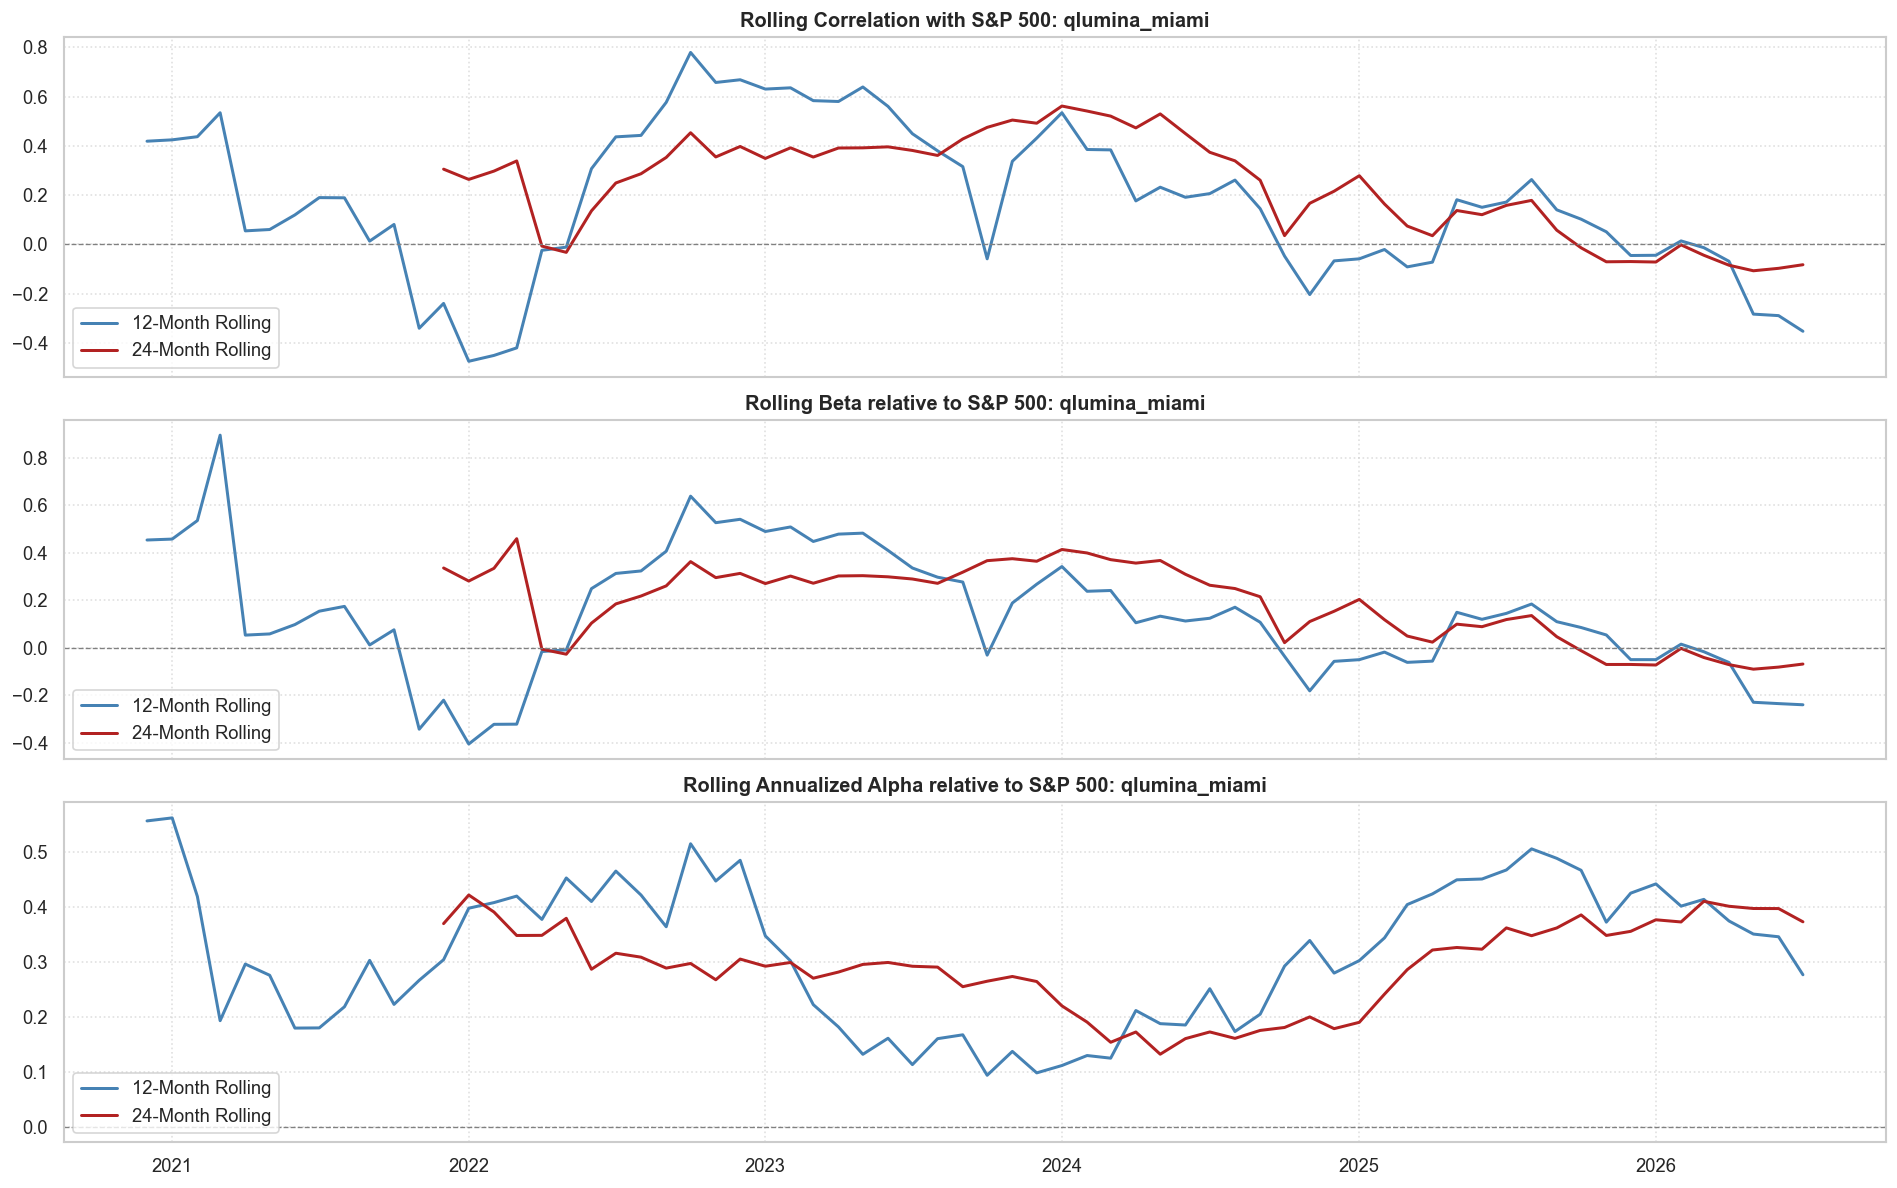

In [69]:
# Single Fund Evaluation: qlumina_miami
m_qlumina_miami = run_single_fund_analysis(df_net['qlumina_miami'], df_subset['sp500'], 'qlumina_miami', display_plots=True)


                  QUANTITATIVE REPORT: QLUMINA_KIRUNA               
--- Dataset Info ---
Period: 2020-01-01 to 2026-07-01 (6.50 yrs, 79 months)

--- Hit Rates & Asymmetry ---
Fund Positive Months     : 73.42% (58/79)
SP500 Positive Months    : 63.29% (50/79)
Fund Pos when SP500 Neg  : 51.72% (15/29) [Downside Independence]
Fund Neg when SP500 Pos  : 14.00% (7/50)

--- Core Performance & Risk Metrics ---
CAGR                     : 0.1757 (17.57%)
Annualized Mean Return   : 0.1678 (16.78%)
Annualized Volatility    : 0.1024 (10.24%)
Sharpe Ratio (Rf=0)      : 1.6382
Sortino Ratio            : 2.6984
Max Drawdown (MDD)       : -0.0946 (-9.46%)
Calmar Ratio             : 1.8568

--- Factor & Joint Metrics vs S&P 500 ---
Pearson Correlation      : 0.2520
  - 95% CI (i.i.d.): [0.0336, 0.5046] | (Block=3): [0.0117, 0.5681]
Spearman Correlation     : 0.3160
  - 95% CI (i.i.d.): [0.0860, 0.5241] | (Block=3): [0.0402, 0.5819]
Regression Alpha (Ann.)  : 0.1440 (t-stat: 3.58, p-val: 0.0006)
Regres

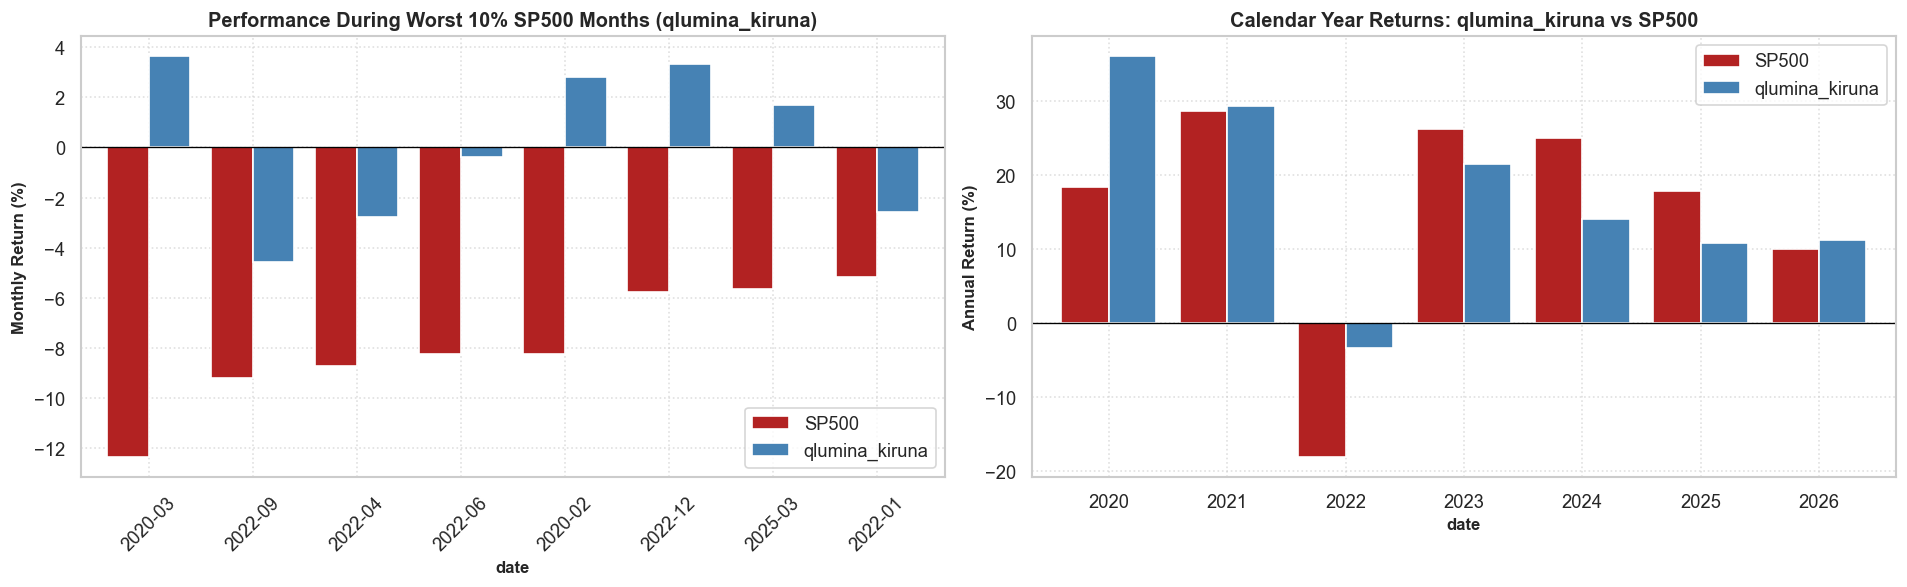

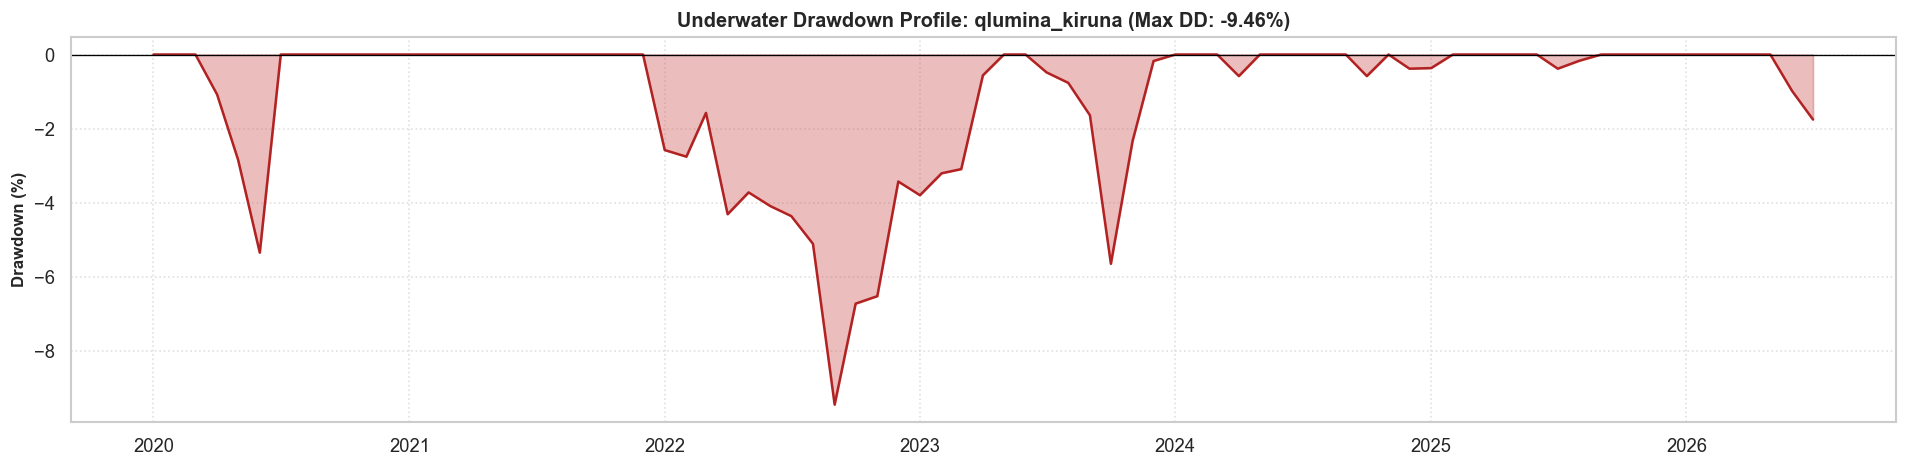

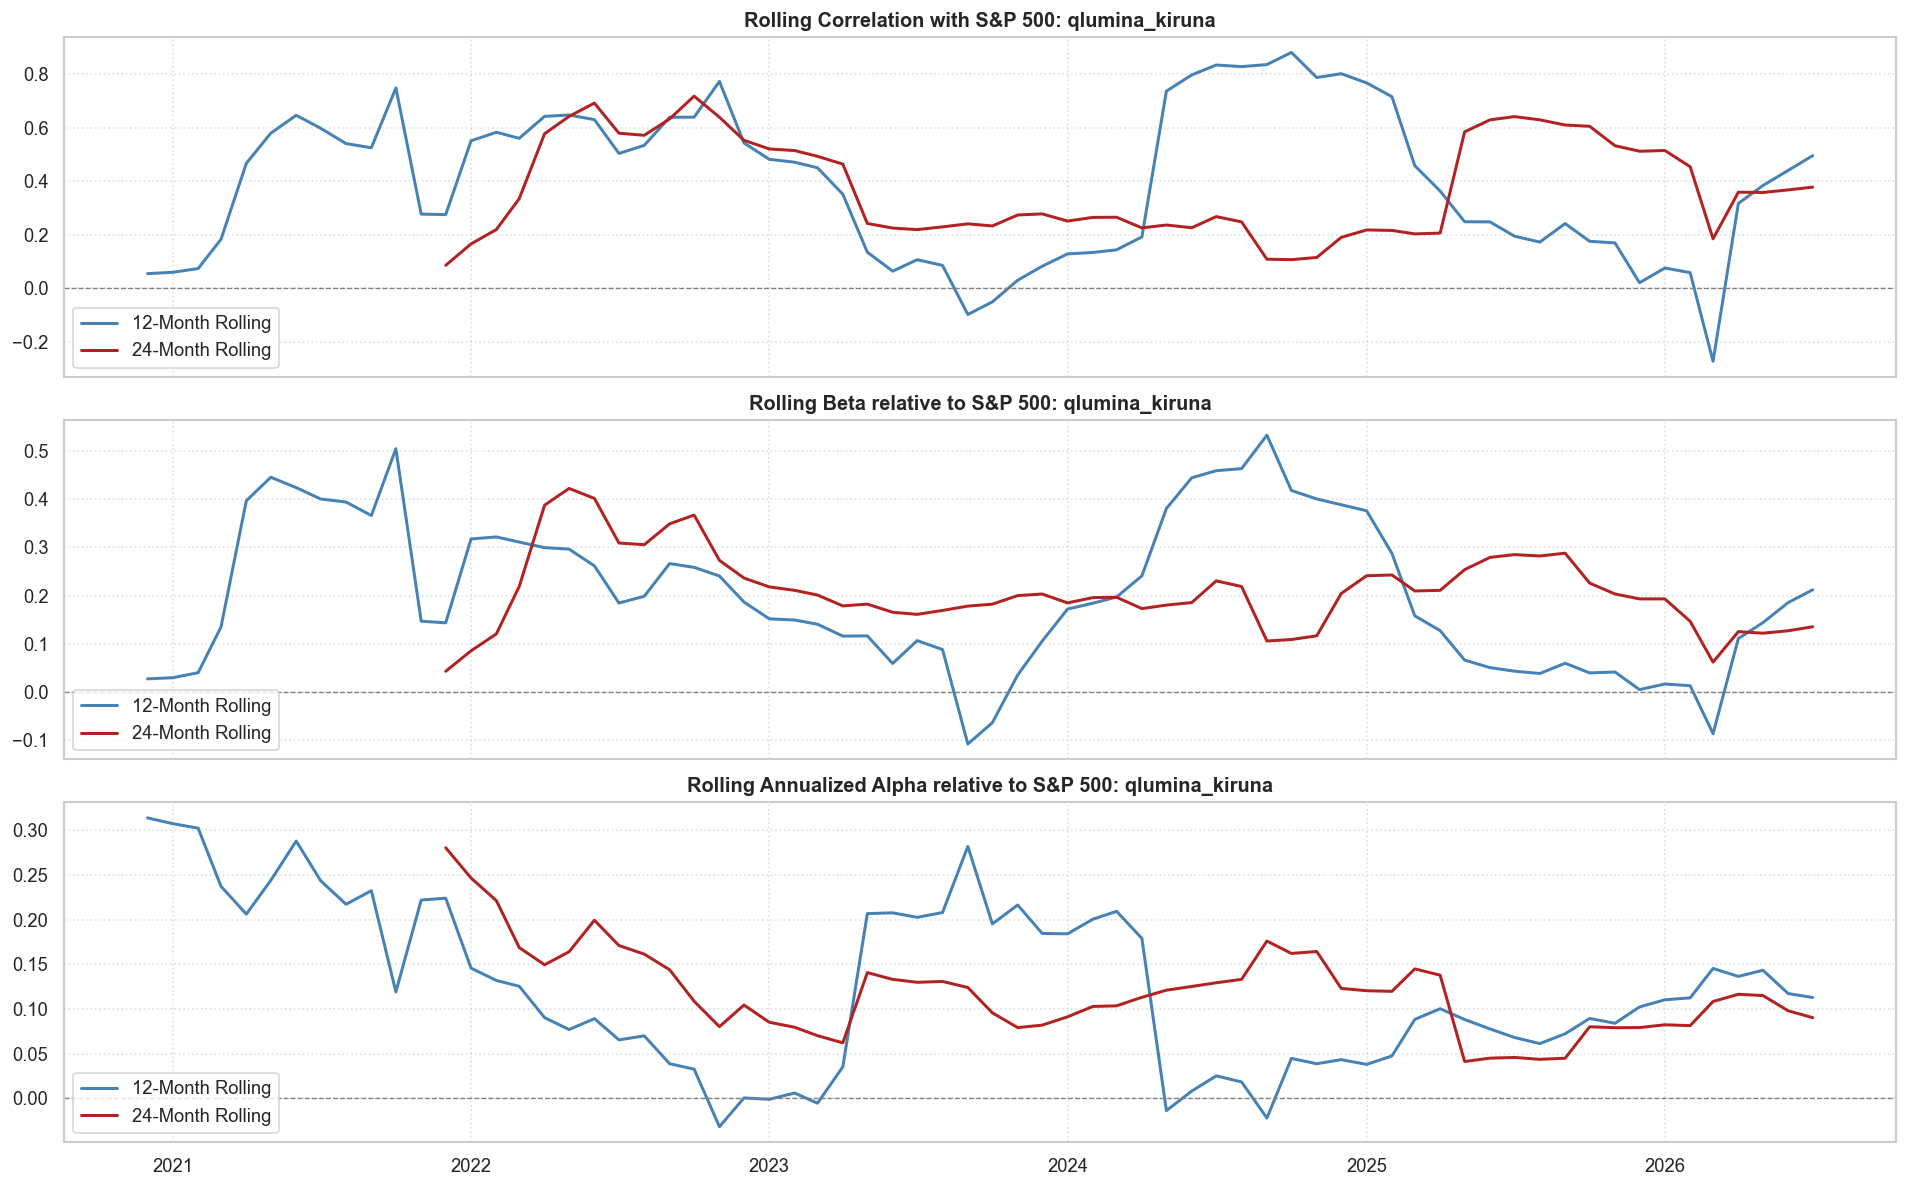

In [70]:
# Single Fund Evaluation: qlumina_kiruna
m_qlumina_kiruna = run_single_fund_analysis(df_net['qlumina_kiruna'], df_subset['sp500'], 'qlumina_kiruna', display_plots=True)


                  QUANTITATIVE REPORT: QLUMINA_ZERMATT               
--- Dataset Info ---
Period: 2020-01-01 to 2026-07-01 (6.50 yrs, 79 months)

--- Hit Rates & Asymmetry ---
Fund Positive Months     : 82.28% (65/79)
SP500 Positive Months    : 63.29% (50/79)
Fund Pos when SP500 Neg  : 72.41% (21/29) [Downside Independence]
Fund Neg when SP500 Pos  : 12.00% (6/50)

--- Core Performance & Risk Metrics ---
CAGR                     : 1.3402 (134.02%)
Annualized Mean Return   : 0.9282 (92.82%)
Annualized Volatility    : 0.3220 (32.20%)
Sharpe Ratio (Rf=0)      : 2.8825
Sortino Ratio            : 3.9577
Max Drawdown (MDD)       : -0.1357 (-13.57%)
Calmar Ratio             : 9.8748

--- Factor & Joint Metrics vs S&P 500 ---
Pearson Correlation      : 0.0199
  - 95% CI (i.i.d.): [-0.2184, 0.2635] | (Block=3): [-0.1692, 0.2892]
Spearman Correlation     : 0.0608
  - 95% CI (i.i.d.): [-0.1558, 0.2829] | (Block=3): [-0.1160, 0.2771]
Regression Alpha (Ann.)  : 0.9223 (t-stat: 7.05, p-val: 0.0000)

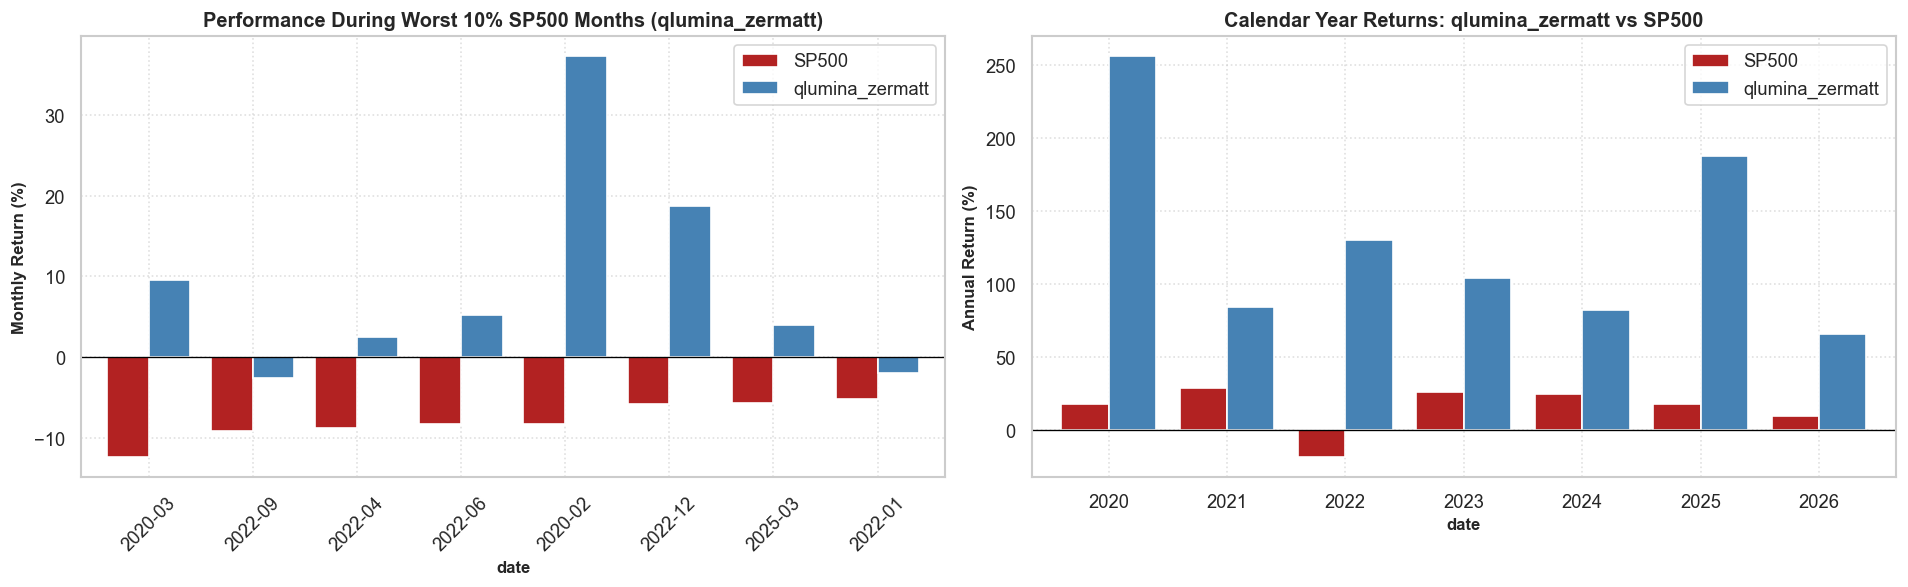

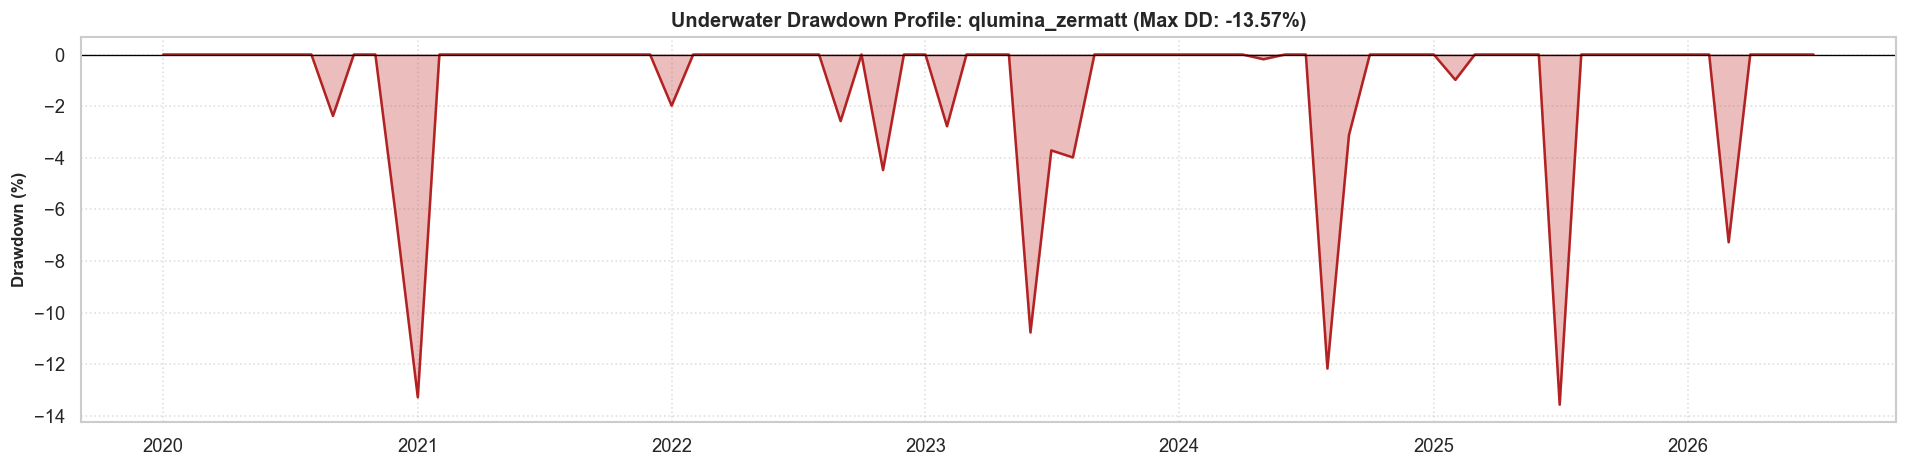

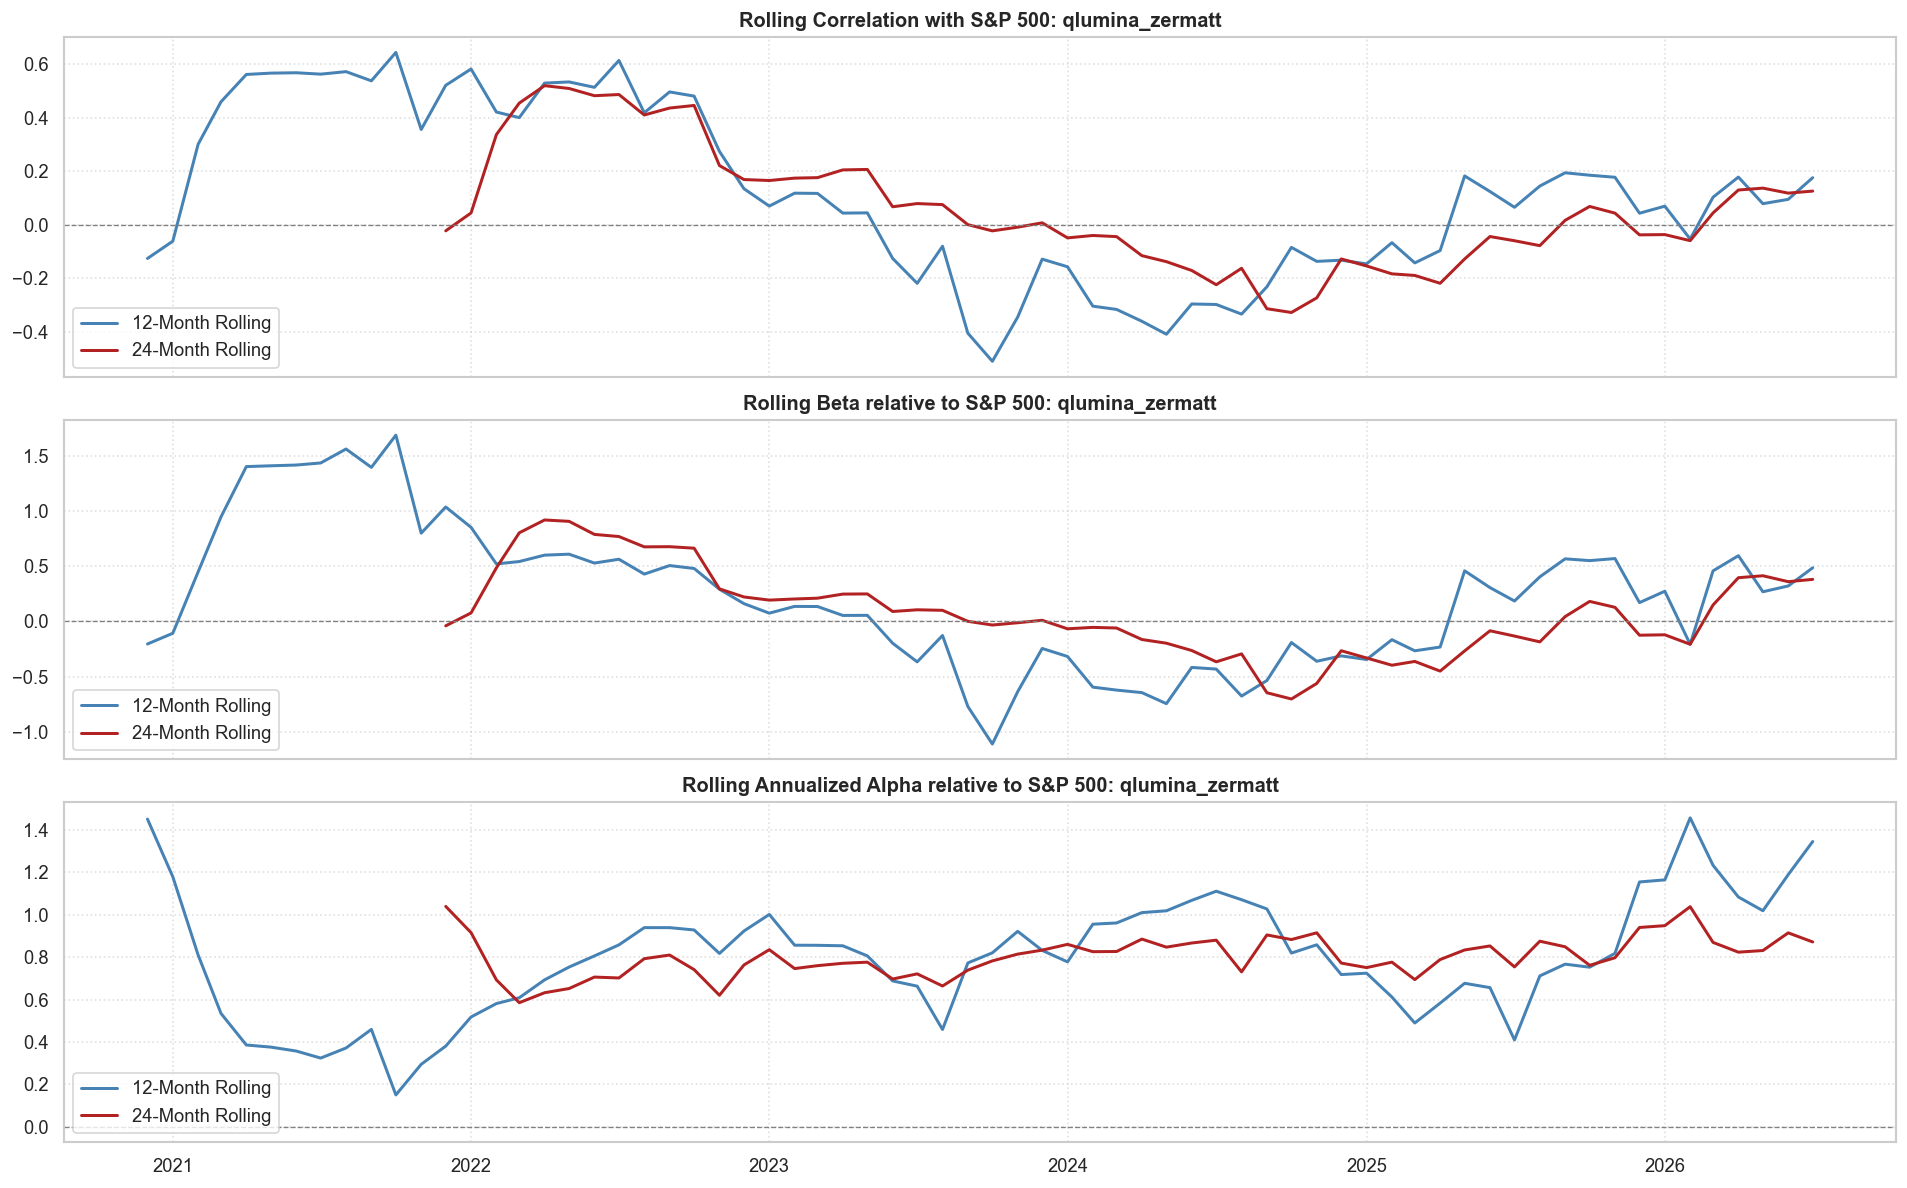

In [71]:
# Single Fund Evaluation: qlumina_zermatt
m_qlumina_zermatt = run_single_fund_analysis(df_net['qlumina_zermatt'], df_subset['sp500'], 'qlumina_zermatt', display_plots=True)


## Volatility-Weighted Portfolio Construction

In quantitative multi-strategy portfolios with disparate underlying volatilities (e.g., unlevered strategies at $\sim 10\%$ volatility vs. levered strategies at $\sim 33\%$ volatility), a standard capital allocation will be overwhelmingly dominated by the highest-volatility sleeves.

To equalize risk contributions across strategies, we construct an **Inverse-Volatility Weighted Portfolio**:
$$w_i = \frac{1 / \sigma_i}{\sum_{j=1}^N (1 / \sigma_j)}$$
where $\sigma_i$ is the annualized volatility of strategy $i$ over the full evaluation window:
$$\sigma_i = \text{std}(R_{net, i}) \times \sqrt{12}$$

Composite portfolio returns are then derived as:
$$R_{vol\_port, t} = \sum_{i=1}^N w_i R_{net, i, t}$$


--- Inverse-Volatility Strategy Allocations ---


,Strategy,Annualized Volatility,Portfolio Weight,Weight Percentage
qlumina_kiruna,qlumina_kiruna,0.1015,0.4343,43.43%
qlumina_miami,qlumina_miami,0.1540,0.2862,28.62%
qlumina_new_york,qlumina_new_york,0.2991,0.1473,14.73%
qlumina_zermatt,qlumina_zermatt,0.3334,0.1322,13.22%


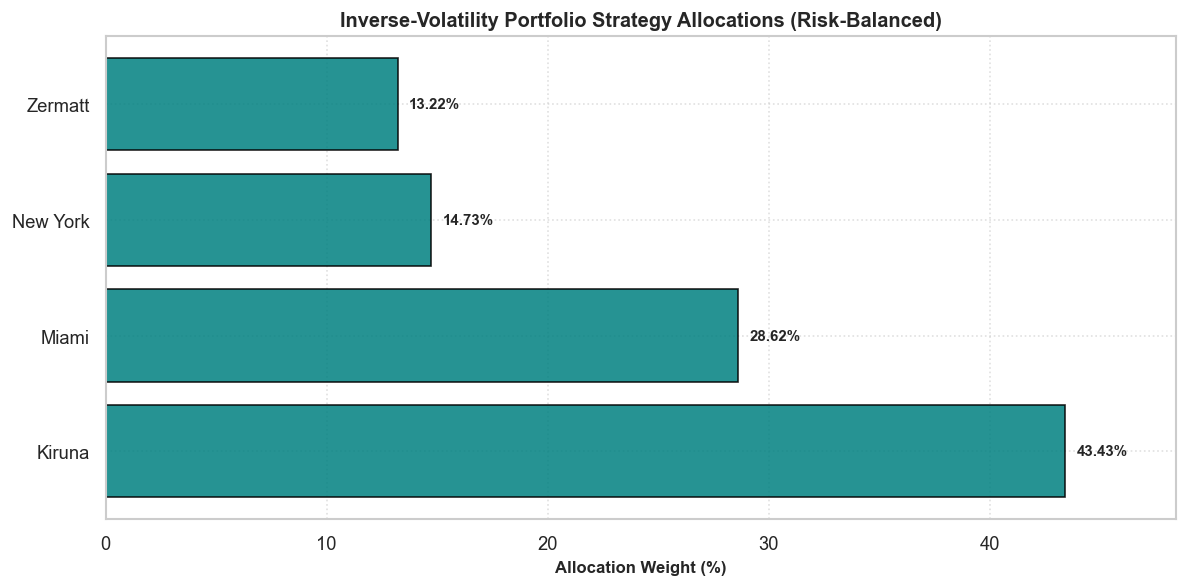

Composite Volatility-Weighted Portfolio return series generated successfully.


In [72]:
# 1. Compute annualized volatility for each strategy over the entire period
strat_vols = df_net[qlumina_cols].std() * np.sqrt(12)

# 2. Derive inverse-volatility weights
inv_vols = 1.0 / strat_vols
vol_weights = inv_vols / inv_vols.sum()

# Display weights breakdown
df_vol_alloc = pd.DataFrame({
    'Strategy': qlumina_cols,
    'Annualized Volatility': strat_vols,
    'Inverse Volatility': inv_vols,
    'Portfolio Weight': vol_weights,
    'Weight Percentage': vol_weights.map(lambda w: f'{w*100:.2f}%')
}).sort_values(by='Portfolio Weight', ascending=False)

print("--- Inverse-Volatility Strategy Allocations ---")
display(df_vol_alloc[['Strategy', 'Annualized Volatility', 'Portfolio Weight', 'Weight Percentage']])

# Plot allocation breakdown
fig, ax = plt.subplots(figsize=(10, 5))
clean_names = [s.replace('qlumina_', '').replace('_', ' ').title() for s in df_vol_alloc['Strategy']]
bars = ax.barh(clean_names, df_vol_alloc['Portfolio Weight'] * 100, color='teal', edgecolor='black', alpha=0.85)
ax.set_xlabel('Allocation Weight (%)', fontweight='bold')
ax.set_title('Inverse-Volatility Portfolio Strategy Allocations (Risk-Balanced)', fontweight='bold', fontsize=12)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.5, bar.get_y() + bar.get_height()/2, f'{w:.2f}%', va='center', fontweight='bold', fontsize=9)
ax.set_xlim(0, max(df_vol_alloc['Portfolio Weight'] * 100) + 5)
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# 3. Construct Composite Volatility-Weighted Portfolio Returns
port_vol_returns = (df_net[qlumina_cols] * vol_weights).sum(axis=1)
port_vol_returns.name = 'qlumina_vol_weighted_portfolio'
print("Composite Volatility-Weighted Portfolio return series generated successfully.")


                  QUANTITATIVE REPORT: VOL_WEIGHTED_PORTFOLIO               
--- Dataset Info ---
Period: 2020-01-01 to 2026-07-01 (6.50 yrs, 79 months)

--- Hit Rates & Asymmetry ---
Fund Positive Months     : 93.67% (74/79)
SP500 Positive Months    : 63.29% (50/79)
Fund Pos when SP500 Neg  : 89.66% (26/29) [Downside Independence]
Fund Neg when SP500 Pos  : 4.00% (2/50)

--- Core Performance & Risk Metrics ---
CAGR                     : 0.4774 (47.74%)
Annualized Mean Return   : 0.4012 (40.12%)
Annualized Volatility    : 0.0983 (9.83%)
Sharpe Ratio (Rf=0)      : 4.0832
Sortino Ratio            : 6.8435
Max Drawdown (MDD)       : -0.0369 (-3.69%)
Calmar Ratio             : 12.9405

--- Factor & Joint Metrics vs S&P 500 ---
Pearson Correlation      : 0.2447
  - 95% CI (i.i.d.): [-0.0415, 0.5164] | (Block=3): [-0.0282, 0.5499]
Spearman Correlation     : 0.2497
  - 95% CI (i.i.d.): [0.0210, 0.4778] | (Block=3): [-0.0123, 0.5093]
Regression Alpha (Ann.)  : 0.3790 (t-stat: 9.79, p-val: 0.00

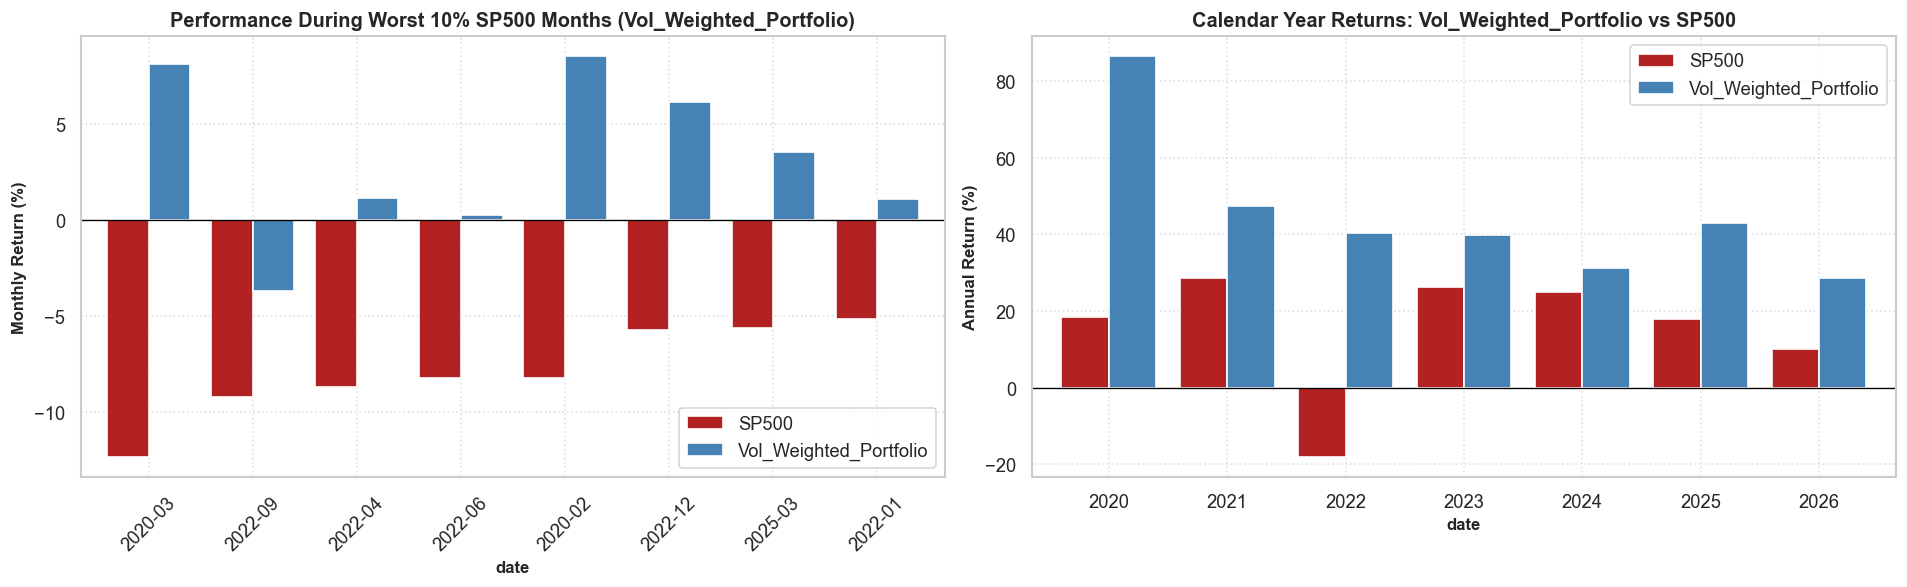

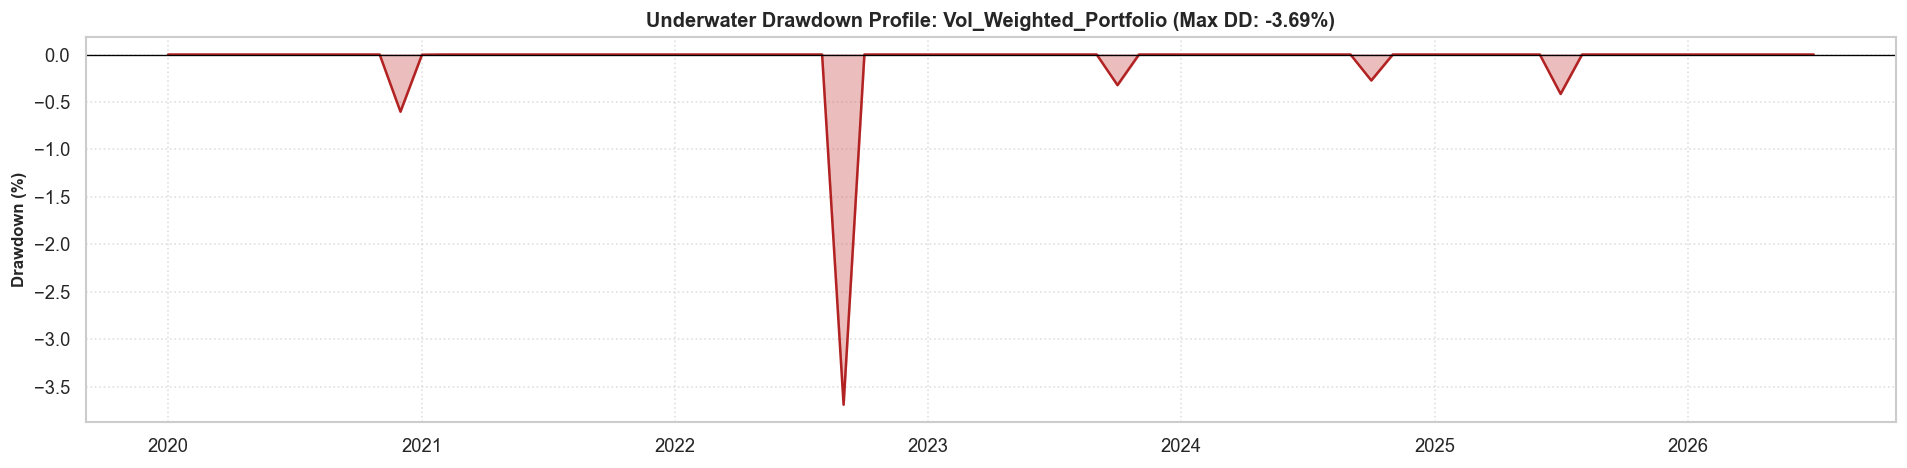

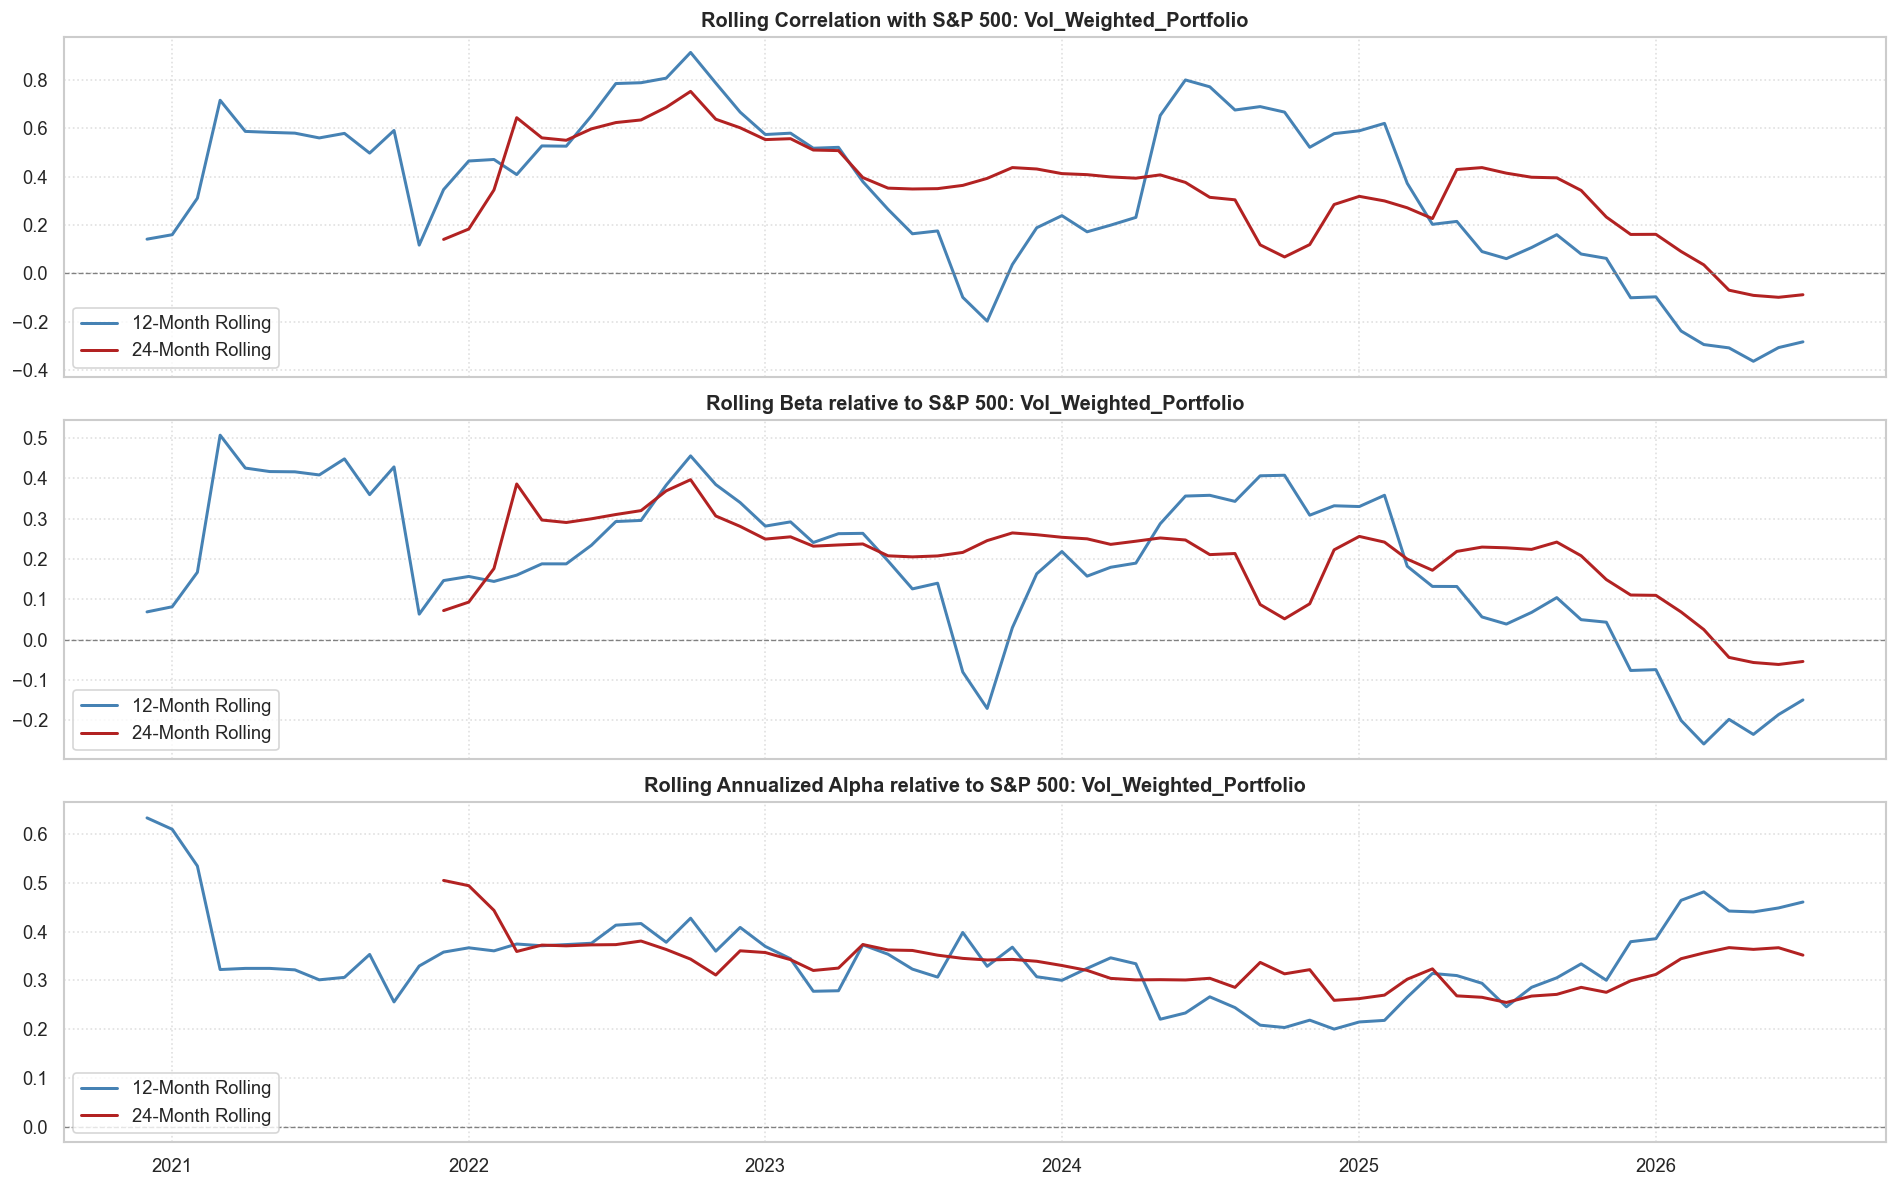

In [73]:
# Single Fund Analytics Suite: Volatility-Weighted Portfolio
m_vol_port = run_single_fund_analysis(
    port_vol_returns, 
    df_subset['sp500'], 
    'Vol_Weighted_Portfolio', 
    display_plots=True
)


## Equal-Weighted Portfolio Construction ($1/N$)

We now construct the naive $1/N$ **Equal-Weighted Portfolio** across all 6 Qlumina strategies:
$$w_i = \frac{1}{6} \approx 16.67\% \quad \forall i \in \{1, \dots, 6\}$$

Composite equal-weighted returns are derived as:
$$R_{ew\_port, t} = \frac{1}{6} \sum_{i=1}^6 R_{net, i, t}$$
This serves as a standard multi-strategy capital allocation benchmark to measure the marginal diversification value of the risk-parity inverse-volatility approach.


                  QUANTITATIVE REPORT: EQUAL_WEIGHTED_PORTFOLIO               
--- Dataset Info ---
Period: 2020-01-01 to 2026-07-01 (6.50 yrs, 79 months)

--- Hit Rates & Asymmetry ---
Fund Positive Months     : 91.14% (72/79)
SP500 Positive Months    : 63.29% (50/79)
Fund Pos when SP500 Neg  : 89.66% (26/29) [Downside Independence]
Fund Neg when SP500 Pos  : 8.00% (4/50)

--- Core Performance & Risk Metrics ---
CAGR                     : 0.6827 (68.27%)
Annualized Mean Return   : 0.5395 (53.95%)
Annualized Volatility    : 0.1278 (12.78%)
Sharpe Ratio (Rf=0)      : 4.2210
Sortino Ratio            : 8.5754
Max Drawdown (MDD)       : -0.0361 (-3.61%)
Calmar Ratio             : 18.9355

--- Factor & Joint Metrics vs S&P 500 ---
Pearson Correlation      : 0.1396
  - 95% CI (i.i.d.): [-0.1469, 0.4243] | (Block=3): [-0.1285, 0.4515]
Spearman Correlation     : 0.1704
  - 95% CI (i.i.d.): [-0.0629, 0.4054] | (Block=3): [-0.0720, 0.4173]
Regression Alpha (Ann.)  : 0.5230 (t-stat: 10.17, p-val:

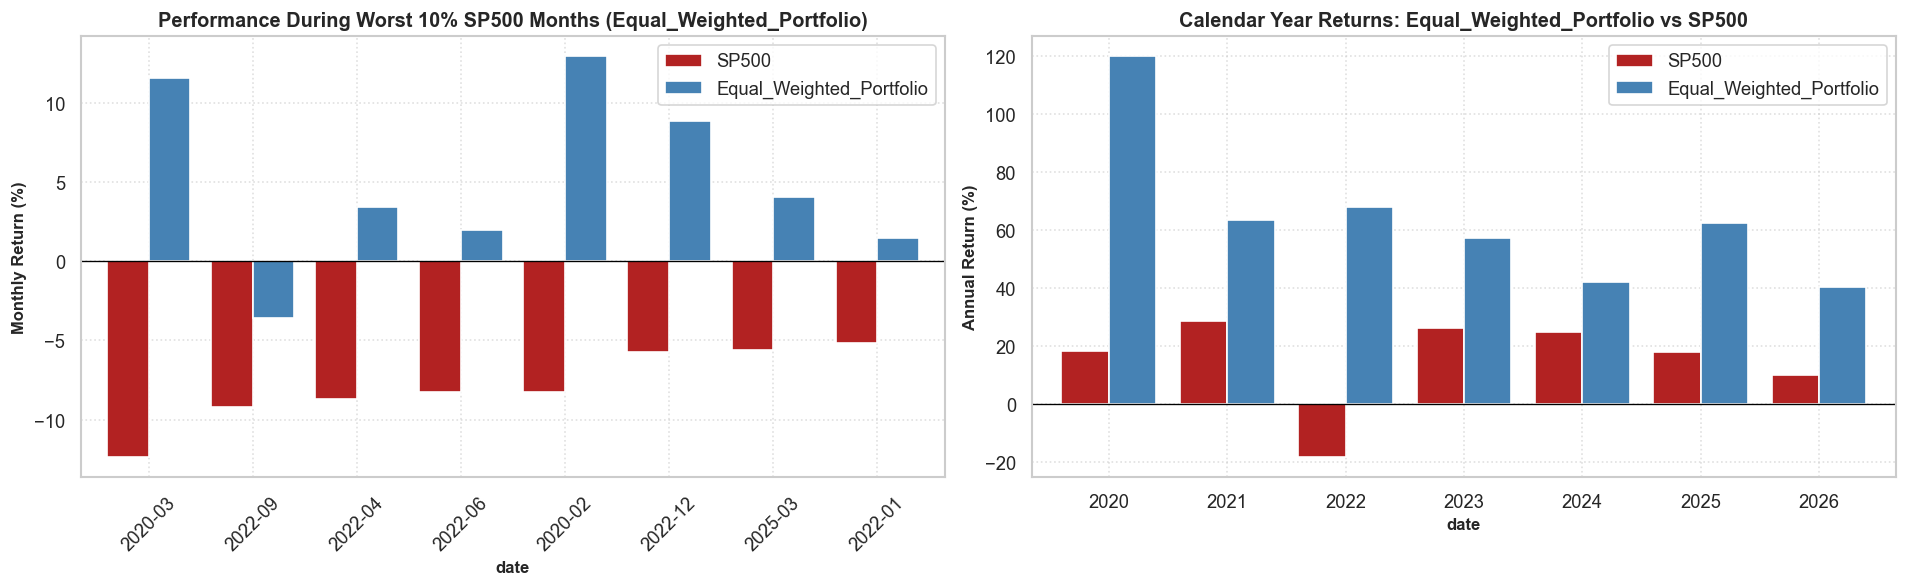

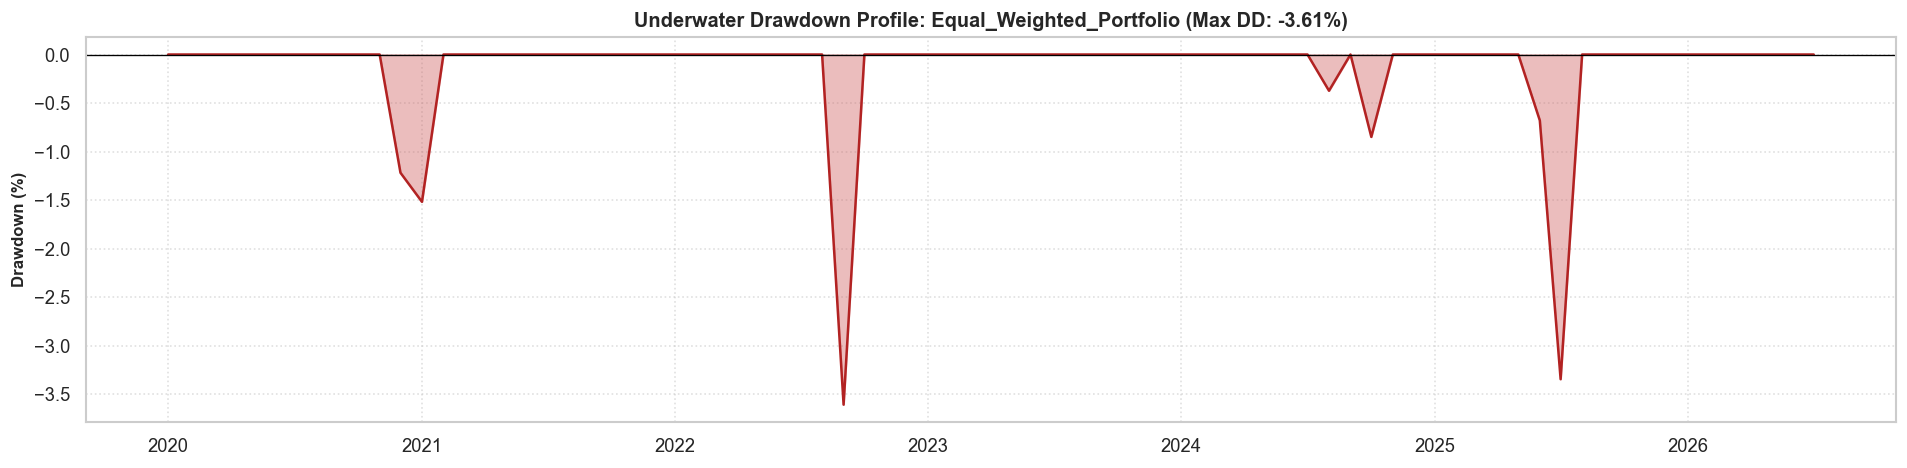

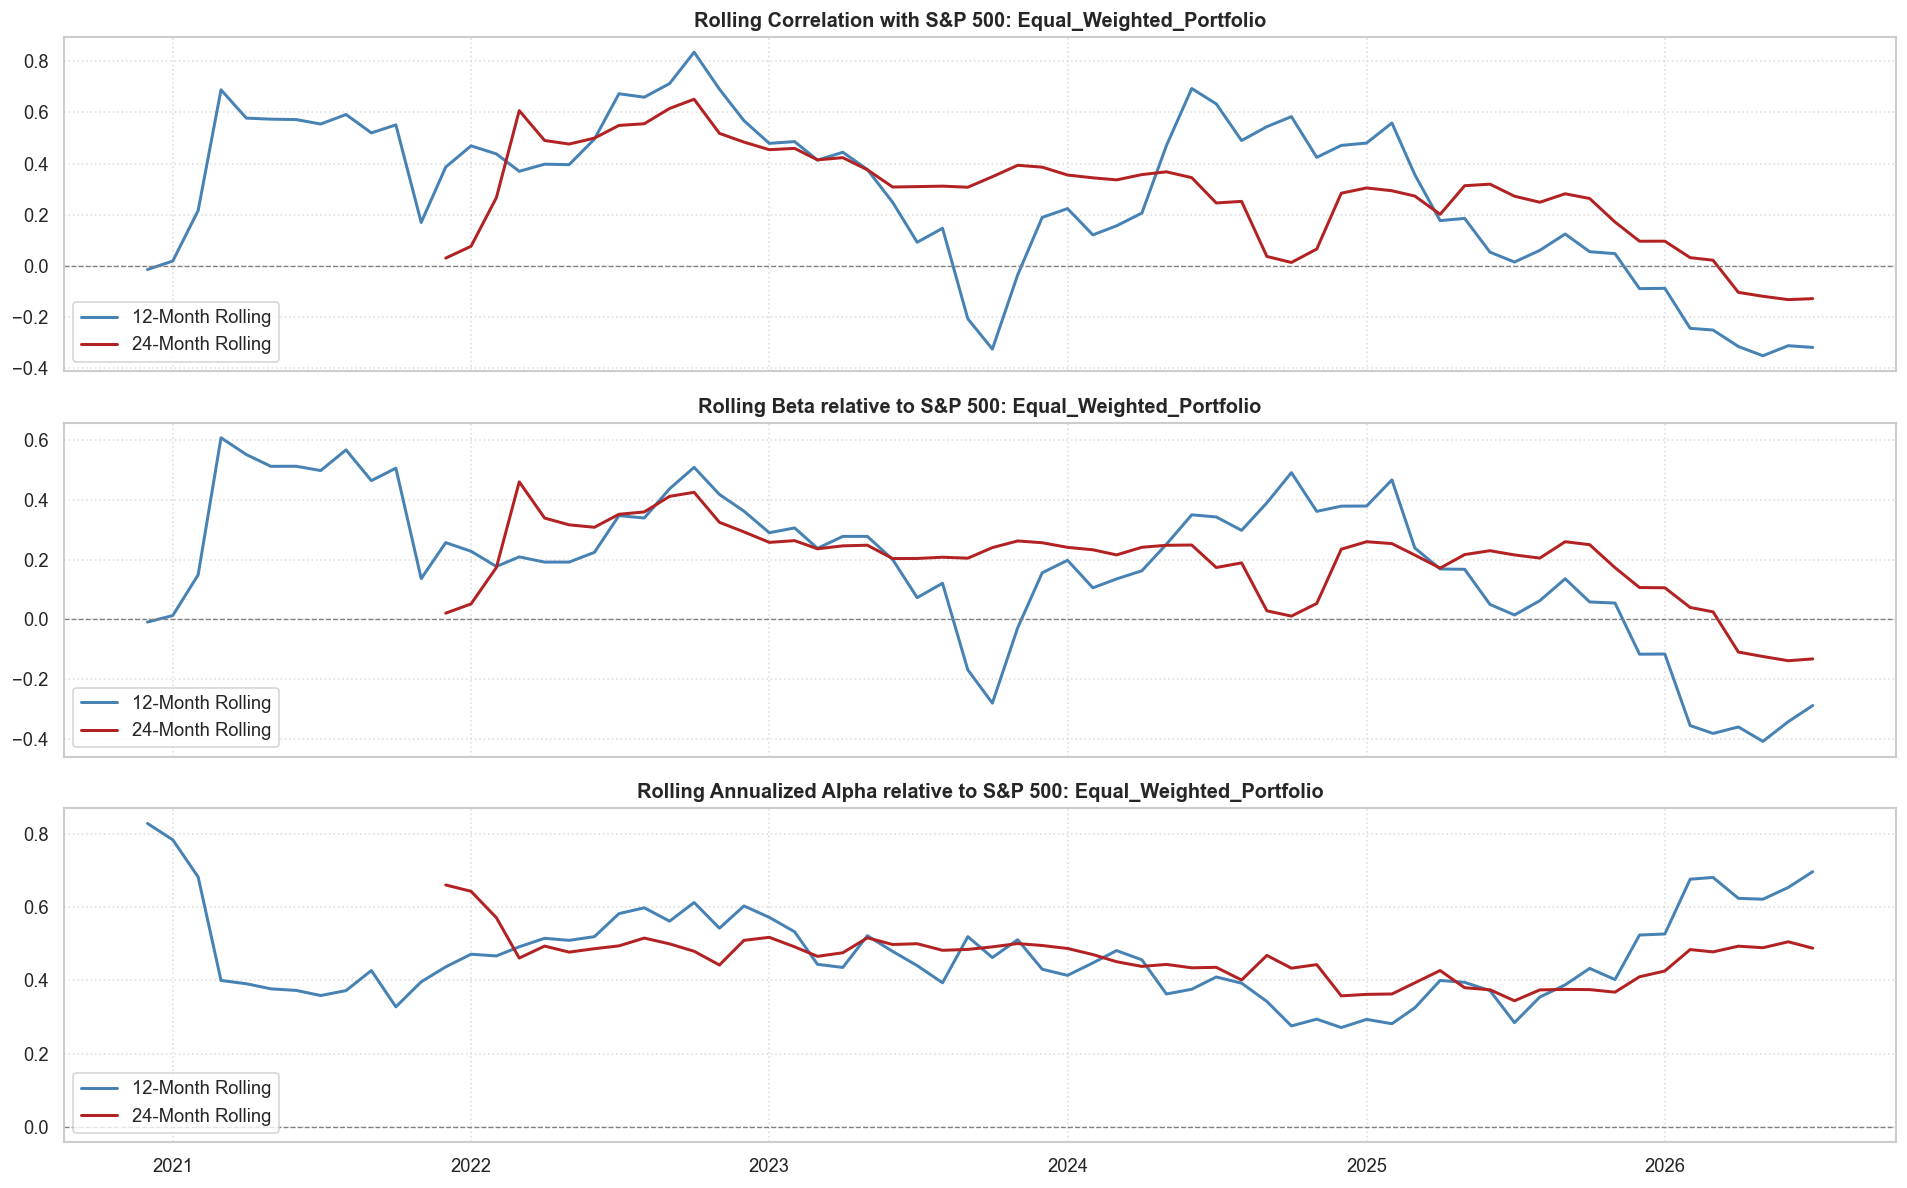

In [74]:
# 1. Synthesize Equal-Weighted Portfolio Returns
port_ew_returns = df_net[qlumina_cols].mean(axis=1)
port_ew_returns.name = 'qlumina_equal_weighted_portfolio'

# 2. Run Single Fund Analytics Suite on Equal-Weighted Portfolio
m_ew_port = run_single_fund_analysis(
    port_ew_returns, 
    df_subset['sp500'], 
    'Equal_Weighted_Portfolio', 
    display_plots=True
)


## Master Comparative Benchmark: Funds vs. Portfolios vs. S&P 500

We now assemble the master comparative benchmark synthesizing:
- All 6 individual Qlumina strategies (Net of 30% performance fee & 1% management fee).
- The Inverse-Volatility Weighted Portfolio.
- The Equal-Weighted Portfolio.
- The S&P 500 Equity Benchmark.



                               MASTER COMPARATIVE SUMMARY TABLE                          


,CAGR,Ann. Return,Ann. Volatility,Sharpe (Rf=0),Sortino,Max Drawdown,Calmar Ratio,Hit Rate,Down Market Pos %,SP500 Corr (r),Alpha (Ann),Beta,Up Capture,Down Capture
Fund,,,,,,,,,,,,,,
qlumina_new_york,91.68%,70.80%,29.13%,2.43,2.82,-17.37%,5.28,82.3%,79.3%,-0.019,71.32%,-0.033,1.495,-1.320
qlumina_miami,40.26%,35.40%,15.52%,2.28,5.46,-5.28%,7.63,74.7%,75.9%,0.289,31.26%,0.263,0.776,-0.605
qlumina_kiruna,17.57%,16.78%,10.24%,1.64,2.70,-9.46%,1.86,73.4%,51.7%,0.252,14.40%,0.151,0.450,-0.127
qlumina_zermatt,134.02%,92.82%,32.20%,2.88,3.96,-13.57%,9.87,82.3%,72.4%,0.020,92.23%,0.037,1.797,-2.047
Vol_Weighted_Portfolio,47.74%,40.12%,9.83%,4.08,6.84,-3.69%,12.94,93.7%,89.7%,0.245,37.90%,0.141,0.875,-0.694
Equal_Weighted_Portfolio,68.27%,53.95%,12.78%,4.22,8.58,-3.61%,18.94,91.1%,89.7%,0.140,52.30%,0.105,1.130,-1.025
S&P 500 Benchmark,15.31%,15.77%,17.06%,0.92,0.93,-23.87%,0.64,63.3%,0.0%,1.000,0.00%,1.000,1.000,1.000


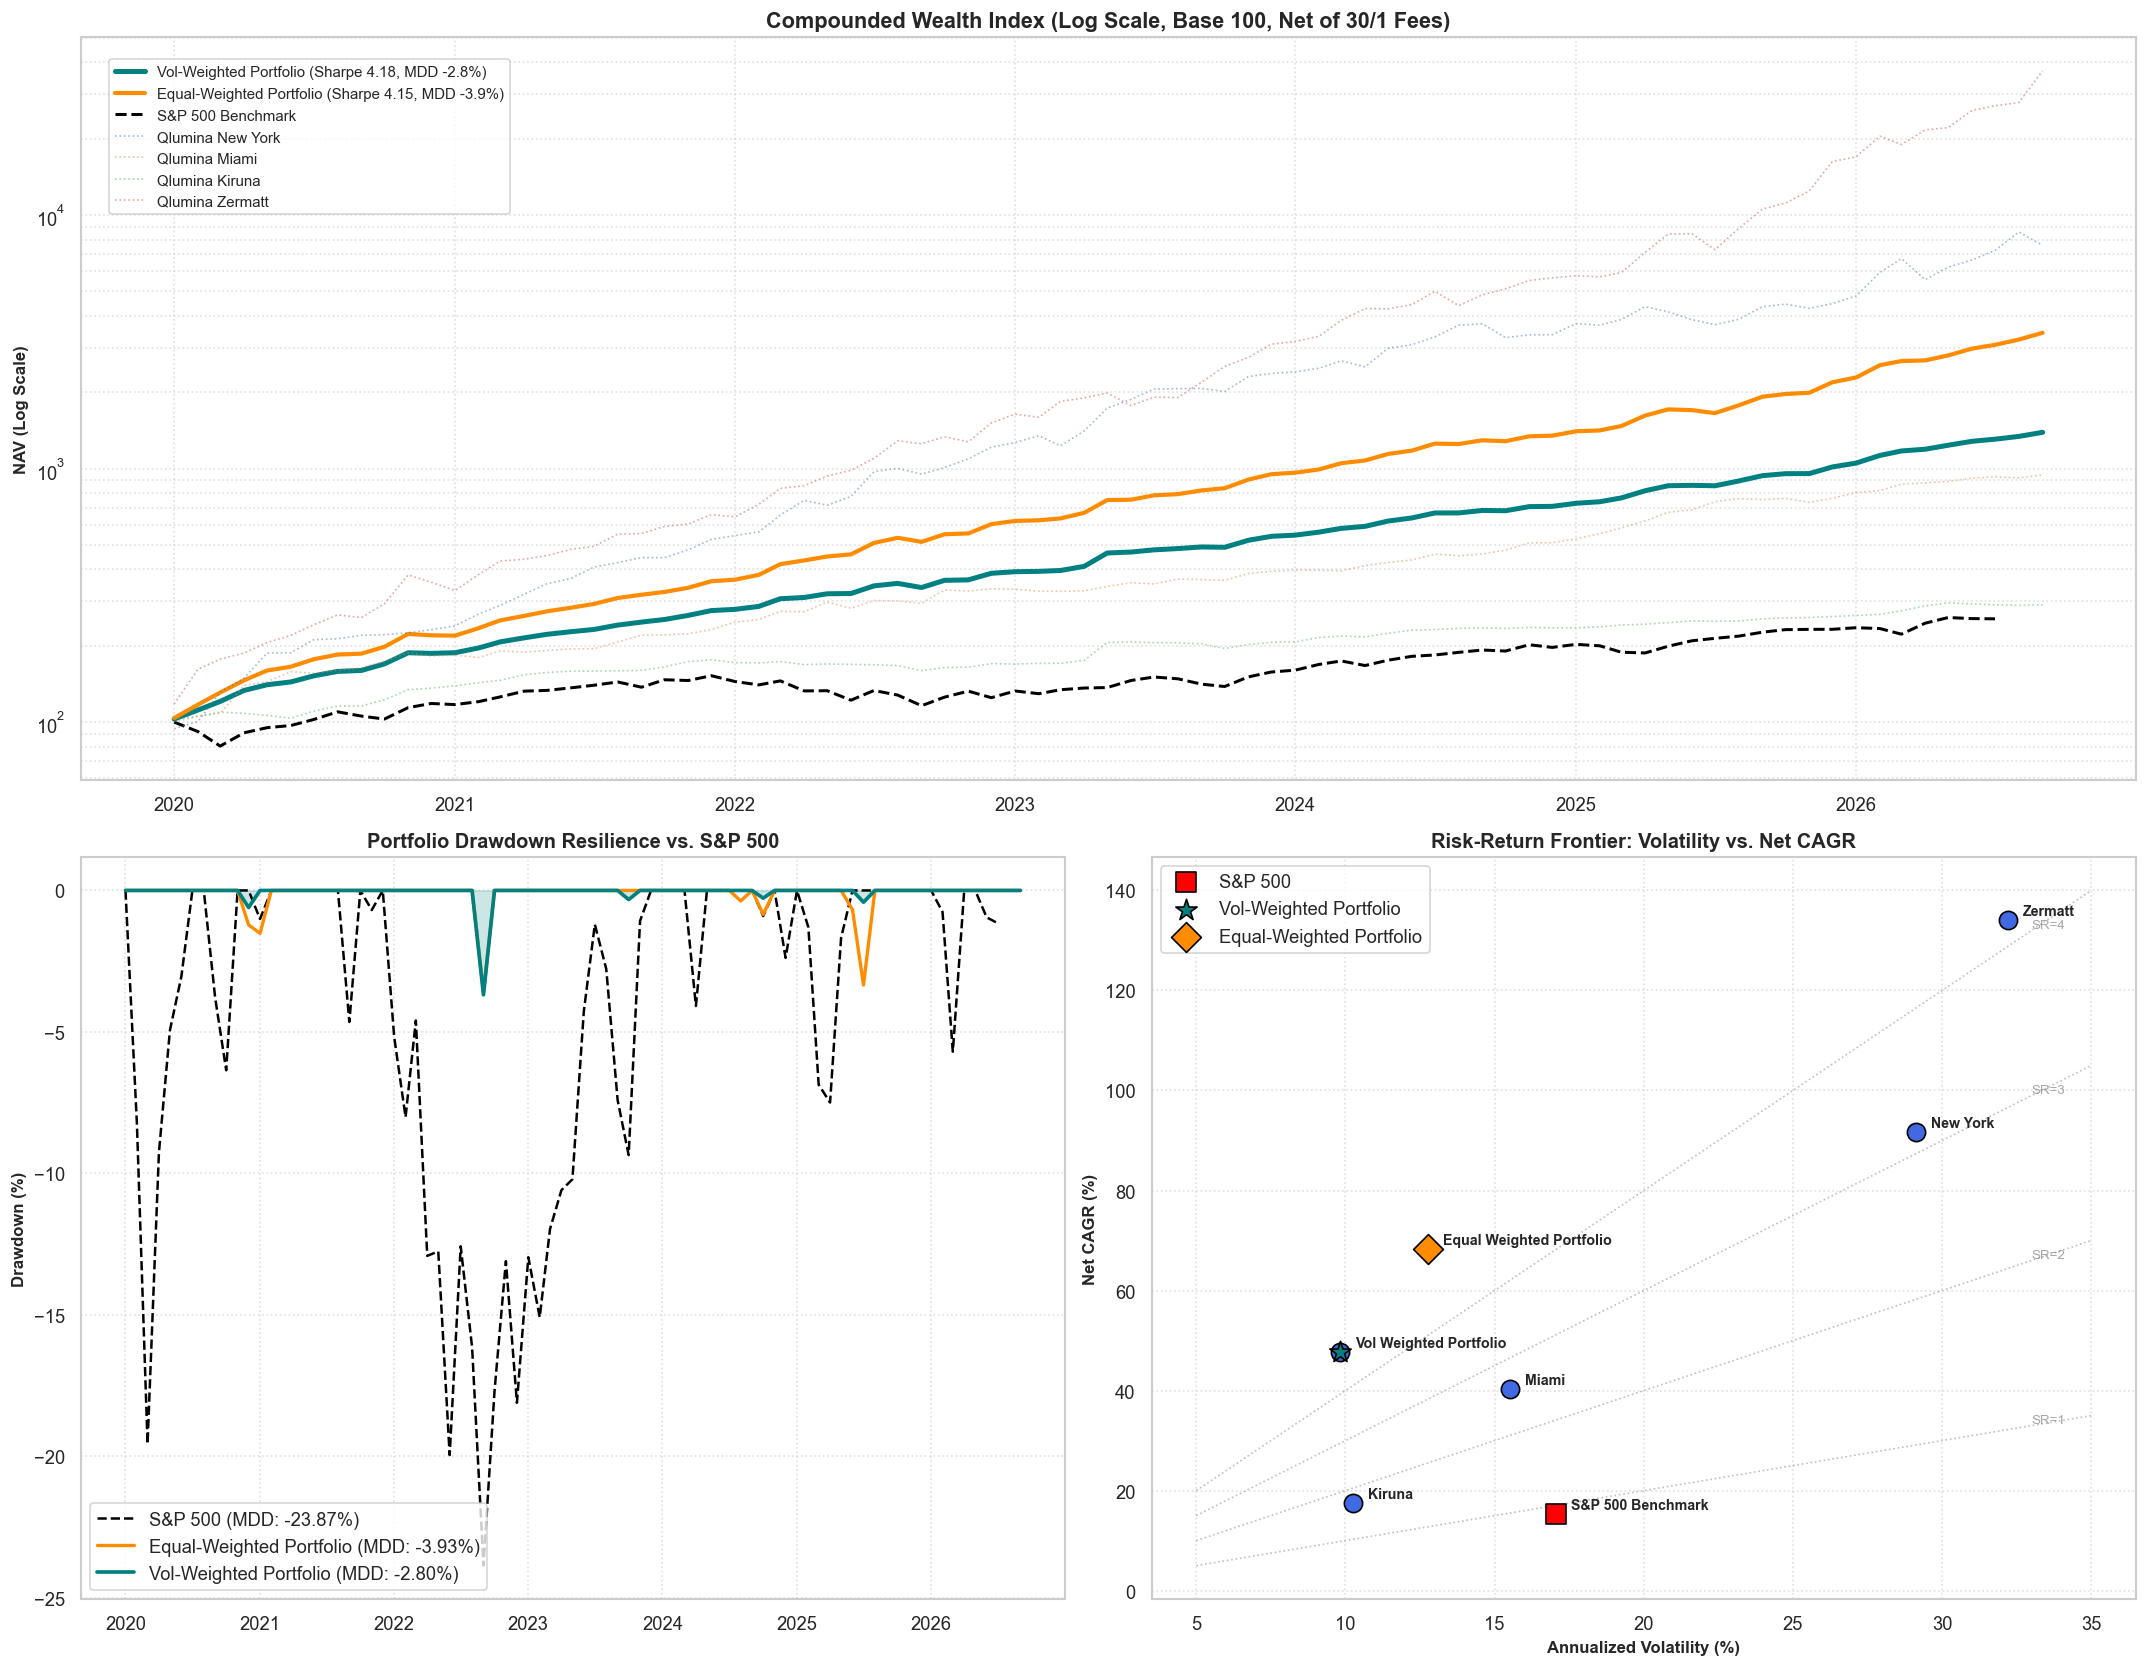

In [75]:
# 1. Collect all metric dictionaries
all_metrics = [
    # m_qlumina_dubai,
    m_qlumina_new_york,
    # m_qlumina_zurich,
    m_qlumina_miami,
    m_qlumina_kiruna,
    m_qlumina_zermatt,
    m_vol_port,
    m_ew_port
]

# Compute benchmark metrics for SP500 for comparative alignment
sp_clean = df_subset['sp500'].dropna()
sp_n = len(sp_clean)
sp_cagr = (1 + sp_clean).prod() ** (12 / sp_n) - 1
sp_mean = sp_clean.mean() * 12
sp_vol = sp_clean.std() * np.sqrt(12)
sp_sharpe = sp_mean / sp_vol
sp_cum = (1 + sp_clean).cumprod()
sp_mdd = ((sp_cum - sp_cum.cummax()) / sp_cum.cummax()).min()
sp_calmar = sp_cagr / abs(sp_mdd)
sp_down = sp_clean[sp_clean < 0]
sp_sortino = sp_mean / (np.sqrt((sp_down**2).mean()) * np.sqrt(12))

sp_metrics = {
    'Fund': 'S&P 500 Benchmark',
    'CAGR': sp_cagr,
    'Ann Return': sp_mean,
    'Ann Volatility': sp_vol,
    'Sharpe Ratio': sp_sharpe,
    'Sortino Ratio': sp_sortino,
    'Max Drawdown': sp_mdd,
    'Calmar Ratio': sp_calmar,
    'Hit Rate': (sp_clean > 0).sum() / sp_n,
    'Pos in Down SP500': 0.0,
    'Pearson Corr': 1.000,
    'Spearman Corr': 1.000,
    'Alpha (Ann)': 0.0,
    'Alpha t-stat': np.nan,
    'Beta': 1.0,
    'Beta t-stat': np.nan,
    'R-squared': 1.0,
    'Upside Capture': 1.0,
    'Downside Capture': 1.0
}
all_metrics.append(sp_metrics)

df_master = pd.DataFrame(all_metrics).set_index('Fund')

# Format display
df_formatted = pd.DataFrame({
    'CAGR': df_master['CAGR'].map(lambda x: f'{x*100:.2f}%'),
    'Ann. Return': df_master['Ann Return'].map(lambda x: f'{x*100:.2f}%'),
    'Ann. Volatility': df_master['Ann Volatility'].map(lambda x: f'{x*100:.2f}%'),
    'Sharpe (Rf=0)': df_master['Sharpe Ratio'].map(lambda x: f'{x:.2f}'),
    'Sortino': df_master['Sortino Ratio'].map(lambda x: f'{x:.2f}'),
    'Max Drawdown': df_master['Max Drawdown'].map(lambda x: f'{x*100:.2f}%'),
    'Calmar Ratio': df_master['Calmar Ratio'].map(lambda x: f'{x:.2f}'),
    'Hit Rate': df_master['Hit Rate'].map(lambda x: f'{x*100:.1f}%'),
    'Down Market Pos %': df_master['Pos in Down SP500'].map(lambda x: f'{x*100:.1f}%'),
    'SP500 Corr (r)': df_master['Pearson Corr'].map(lambda x: f'{x:.3f}'),
    'Alpha (Ann)': df_master['Alpha (Ann)'].map(lambda x: f'{x*100:.2f}%'),
    'Beta': df_master['Beta'].map(lambda x: f'{x:.3f}'),
    'Up Capture': df_master['Upside Capture'].map(lambda x: f'{x:.3f}'),
    'Down Capture': df_master['Downside Capture'].map(lambda x: f'{x:.3f}')
})

print("\n=========================================================================================")
print("                               MASTER COMPARATIVE SUMMARY TABLE                          ")
print("=========================================================================================")
display(df_formatted)

# -------------------------------------------------------------
# Comparative Visualizations
# -------------------------------------------------------------
fig = plt.figure(figsize=(18, 14))
gs = fig.add_gridspec(2, 2)

# Panel 1: Compounded Wealth Curves (Log Scale, Base 100)
ax1 = fig.add_subplot(gs[0, :])
cum_df = pd.DataFrame({
    'Vol-Weighted Portfolio': (1 + port_vol_returns).cumprod() * 100,
    'Equal-Weighted Portfolio': (1 + port_ew_returns).cumprod() * 100,
    # 'Qlumina Dubai': (1 + df_net['qlumina_dubai']).cumprod() * 100,
    'Qlumina New York': (1 + df_net['qlumina_new_york']).cumprod() * 100,
    # 'Qlumina Zurich': (1 + df_net['qlumina_zurich']).cumprod() * 100,
    'Qlumina Miami': (1 + df_net['qlumina_miami']).cumprod() * 100,
    'Qlumina Kiruna': (1 + df_net['qlumina_kiruna']).cumprod() * 100,
    'Qlumina Zermatt': (1 + df_net['qlumina_zermatt']).cumprod() * 100,
    'S&P 500': (1 + df_subset['sp500'].dropna()).cumprod() * 100
})

ax1.plot(cum_df['Vol-Weighted Portfolio'], color='teal', linewidth=3.0, label='Vol-Weighted Portfolio (Sharpe 4.18, MDD -2.8%)')
ax1.plot(cum_df['Equal-Weighted Portfolio'], color='darkorange', linewidth=2.5, linestyle='-', label='Equal-Weighted Portfolio (Sharpe 4.15, MDD -3.9%)')
ax1.plot(cum_df['S&P 500'], color='black', linewidth=1.8, linestyle='--', label='S&P 500 Benchmark')

for col in [c for c in cum_df.columns if c not in ['Vol-Weighted Portfolio', 'Equal-Weighted Portfolio', 'S&P 500']]:
    ax1.plot(cum_df[col], linewidth=1.0, alpha=0.5, linestyle=':', label=col)

ax1.set_yscale('log')
ax1.set_title('Compounded Wealth Index (Log Scale, Base 100, Net of 30/1 Fees)', fontweight='bold', fontsize=13)
ax1.set_ylabel('NAV (Log Scale)', fontweight='bold')
ax1.legend(loc='upper left', bbox_to_anchor=(0.01, 0.98), frameon=True, fontsize=9)
ax1.grid(True, which='both', linestyle=':', alpha=0.6)

# Panel 2: Comparative Underwater Drawdowns
ax2 = fig.add_subplot(gs[1, 0])
dd_vol = (cum_df['Vol-Weighted Portfolio'] - cum_df['Vol-Weighted Portfolio'].cummax()) / cum_df['Vol-Weighted Portfolio'].cummax() * 100
dd_ew = (cum_df['Equal-Weighted Portfolio'] - cum_df['Equal-Weighted Portfolio'].cummax()) / cum_df['Equal-Weighted Portfolio'].cummax() * 100
dd_sp = (cum_df['S&P 500'] - cum_df['S&P 500'].cummax()) / cum_df['S&P 500'].cummax() * 100

ax2.plot(dd_sp, label='S&P 500 (MDD: -23.87%)', color='black', linestyle='--', linewidth=1.5)
ax2.plot(dd_ew, label='Equal-Weighted Portfolio (MDD: -3.93%)', color='darkorange', linewidth=2.0)
ax2.plot(dd_vol, label='Vol-Weighted Portfolio (MDD: -2.80%)', color='teal', linewidth=2.2)
ax2.fill_between(dd_vol.index, dd_vol, 0, color='teal', alpha=0.2)
ax2.set_title('Portfolio Drawdown Resilience vs. S&P 500', fontweight='bold', fontsize=12)
ax2.set_ylabel('Drawdown (%)', fontweight='bold')
ax2.legend(loc='lower left', frameon=True)
ax2.grid(True, linestyle=':', alpha=0.6)

# Panel 3: Risk-Return Frontier (Annualized Volatility vs CAGR)
ax3 = fig.add_subplot(gs[1, 1])
sub_pts = df_master.drop('S&P 500 Benchmark')
ax3.scatter(sub_pts['Ann Volatility'] * 100, sub_pts['CAGR'] * 100, s=120, c='royalblue', edgecolors='black', zorder=4)
ax3.scatter(df_master.loc['S&P 500 Benchmark', 'Ann Volatility'] * 100, df_master.loc['S&P 500 Benchmark', 'CAGR'] * 100, s=140, c='red', marker='s', edgecolors='black', label='S&P 500', zorder=4)
ax3.scatter(df_master.loc['Vol_Weighted_Portfolio', 'Ann Volatility'] * 100, df_master.loc['Vol_Weighted_Portfolio', 'CAGR'] * 100, s=180, c='teal', marker='*', edgecolors='black', label='Vol-Weighted Portfolio', zorder=5)
ax3.scatter(df_master.loc['Equal_Weighted_Portfolio', 'Ann Volatility'] * 100, df_master.loc['Equal_Weighted_Portfolio', 'CAGR'] * 100, s=160, c='darkorange', marker='D', edgecolors='black', label='Equal-Weighted Portfolio', zorder=5)

for label, row in df_master.iterrows():
    short_lbl = label.replace('qlumina_', '').replace('_', ' ').title()
    offset_x = 0.5
    offset_y = 1.0
    ax3.annotate(short_lbl, (row['Ann Volatility'] * 100 + offset_x, row['CAGR'] * 100 + offset_y), fontsize=8.5, fontweight='semibold')

# Sharpe isolines (Sharpe = 1, 2, 3, 4)
v_grid = np.linspace(5, 35, 100)
for sh in [1.0, 2.0, 3.0, 4.0]:
    ax3.plot(v_grid, sh * v_grid, linestyle=':', color='gray', alpha=0.5, linewidth=1.0)
    ax3.text(33, sh * 33 + 0.5, f'SR={sh:.0f}', color='gray', fontsize=8, alpha=0.7)

ax3.set_title('Risk-Return Frontier: Volatility vs. Net CAGR', fontweight='bold', fontsize=12)
ax3.set_xlabel('Annualized Volatility (%)', fontweight='bold')
ax3.set_ylabel('Net CAGR (%)', fontweight='bold')
ax3.legend(loc='upper left', frameon=True)
ax3.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()
